# 02 — Entrenamiento por versión del dataset (v2 = con data augmentation) · 6 marcas de cerveza con YOLO26

**Trabajo de IA (Universidad EIA)**: Águila, Club Colombia, Póker, Andina, Costeña y Heineken.

Este notebook sigue **el mismo orden del notebook de clase** (`ExampleRoboflow_BCCD_YOLO.ipynb`):

| Clase (BCCD) | Aquí (cervezas) |
|---|---|
| Revisar GPU e instalar `ultralytics` | Igual, pero en el **PC de Fraquiem** (RTX 4060) en vez de Colab |
| Descargar el dataset de Roboflow (`curl` + `unzip`) | Igual, con Python (funciona en Windows) |
| Ver imágenes, `img.shape`, leer `data.yaml` | Igual |
| Cambiar los `..` del `data.yaml` por la ruta completa | Igual, explicado paso a paso |
| `model.train(data, epochs, imgsz, project, name)` | Igual, con **dos modelos**: **nano** y **small** |
| `results.png`, `train_batch0`, `model.val()`, `map`, matriz de confusión | Igual, más el umbral de confianza |
| Inferencia en las imágenes de *test* | Igual, con `model.predict` (no el `detect.py` viejo de YOLOv5) |
| — | Comparar nano vs. small, guardar los modelos y probar en vivo con la webcam (720p) |

**Cómo usarlo:** editar solo la celda **1. Configuración** y ejecutar de arriba hacia abajo.
Mismo notebook que el 01, pero **todo depende de la variable `VERSION`**: carpetas de resultados (`nano_v2`,
`small_v2`), nombres de los modelos guardados (`cervezas_nano_v2.pt`) y la tabla de comparación. Para una versión
nueva del dataset solo se cambian `VERSION` y el enlace o zip de esa versión.

## 1. Configuración
Lo único que hay que editar. En Windows las rutas van como `r"C:\..."`.
- `ROBOFLOW_URL`: el enlace de descarga del dataset. En Roboflow: *Versions → Export Dataset → formato YOLO
  (Ultralytics, p. ej. "YOLOv8") → Show download code → Terminal*. Es la dirección que va entre comillas después de
  `curl -L` (igual a la del notebook de clase). **No la publiquen: incluye la llave de acceso del proyecto.**
- Si prefieren bajar el `.zip` a mano, dejen `ROBOFLOW_URL = ""` y pongan su ruta en `ZIP_MANUAL`.

In [1]:
from pathlib import Path

VERSION = "v4"                                      # modelos v4 = entrenados con el dataset v4 de Roboflow (110 fotos, 70/20/10)
ROBOFLOW_URL = ""                                   # enlace de ESA versión: "https://app.roboflow.com/ds/XXXX?key=YYYY"
ZIP_MANUAL = r""                                    # o la ruta del .zip descargado a mano
DATASET_DIR = Path(r"C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8")   # una carpeta POR versión del dataset

# Igual que en clase: path = carpeta de resultados, subpath = nombre de cada entrenamiento.
# OJO: debe ser una carpeta del PC de Fraquiem que NO se borre (ahí quedan los modelos entrenados).
path = Path(r"C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version")      # ¡cambiar! (en el 01 quedó la ruta de ejemplo)
subpath_nano = f"nano_{VERSION}"
subpath_small = f"small_{VERSION}"

EPOCAS = 200        # entre 100 y 300; con PACIENCIA=50 para solo si deja de mejorar y se queda con best.pt
PACIENCIA = 50      # si 50 épocas seguidas no mejora, para solo y se queda con el mejor
IMGSZ = 640         # tamaño de entrada del modelo (mínimo 426 por regla de la clase)
BATCH = -1          # -1 = automático según la memoria de la GPU (en CPU se cambia a 8)
WORKERS = 2         # si en Windows sale un error de "DataLoader", poner 0

path.mkdir(parents=True, exist_ok=True)

## 2. Revisar la GPU e instalar YOLO
Como en clase (`!nvidia-smi` y `ultralytics.checks()`). En el PC de Fraquiem debe aparecer la **RTX 4060**.
Si dice que no hay GPU, `torch` quedó instalado **sin CUDA**: instalarlo con el comando de
<https://pytorch.org/get-started/locally/> (Windows, pip, CUDA).

In [2]:
!nvidia-smi

Sat Oct 31 18:11:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 572.40                 Driver Version: 572.40         CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   42C    P8              4W /   60W |       2MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# %pip install ultralytics       # descomentar solo si no está instalado
import ultralytics, torch
ultralytics.checks()

GPU = torch.cuda.is_available()
DEVICE = 0 if GPU else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if GPU else "NO HAY GPU (se entrenará en CPU, mucho más lento)")
if not GPU and BATCH == -1:
    BATCH = 8

Ultralytics 8.4.196  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


Setup complete  (12 CPUs, 31.6 GB RAM, 341.6/475.8 GB disk)


GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [4]:
import os, glob, shutil, zipfile, urllib.request, time, csv, random
import numpy as np
import matplotlib.pyplot as plt
import cv2
import yaml
from PIL import Image
from IPython.display import Image as IPyImage, display
from ultralytics import YOLO


def mostrar(ruta, ancho=900):
    """Muestra una imagen guardada (como Image(filename=...) en el notebook de clase)."""
    ruta = Path(ruta)
    if ruta.exists():
        print(ruta.name)
        display(IPyImage(filename=str(ruta), width=ancho))
    else:
        print("(no existe)", ruta)

## 3. Descargar el dataset de Roboflow
En clase: `!curl -L "<enlace>" > BCCD.zip` y `!unzip BCCD.zip -d /content/BCCD/`. Aquí se hace lo mismo con
Python, porque Windows no trae `unzip`. Si el dataset ya está descomprimido, esta celda no hace nada.

Al descomprimir quedan `train/`, `valid/` y `test/` (cada una con `images/` y `labels/`) y el archivo `data.yaml`.

In [5]:
if (DATASET_DIR / "data.yaml").exists():
    print("El dataset ya está en", DATASET_DIR)
else:
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if ROBOFLOW_URL:
        zip_path = DATASET_DIR.parent / (DATASET_DIR.name + ".zip")
        print("Descargando de Roboflow...")
        req = urllib.request.Request(ROBOFLOW_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp, open(zip_path, "wb") as f:
            shutil.copyfileobj(resp, f)
    else:
        zip_path = Path(ZIP_MANUAL)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATASET_DIR)
    print("Descomprimido en", DATASET_DIR)

print(sorted(p.name for p in DATASET_DIR.iterdir()))

El dataset ya está en C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8
['README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']


Ver una imagen y su tamaño (`img.shape` = alto, ancho, canales), como en clase.

77 imágenes de entrenamiento


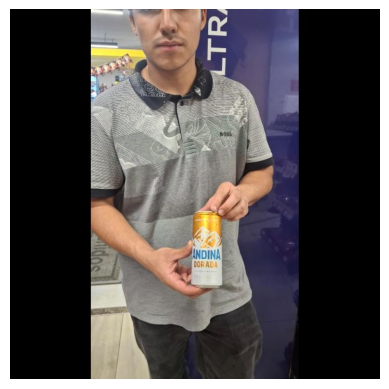

(640, 640, 3)

In [6]:
EXT = ("*.jpg", "*.jpeg", "*.png")
image_paths = sorted(p for e in EXT for p in glob.glob(str(DATASET_DIR / "train" / "images" / e)))
print(len(image_paths), "imágenes de entrenamiento")

img = plt.imread(image_paths[0])
plt.figure(); plt.imshow(img); plt.axis("off"); plt.show()
img.shape

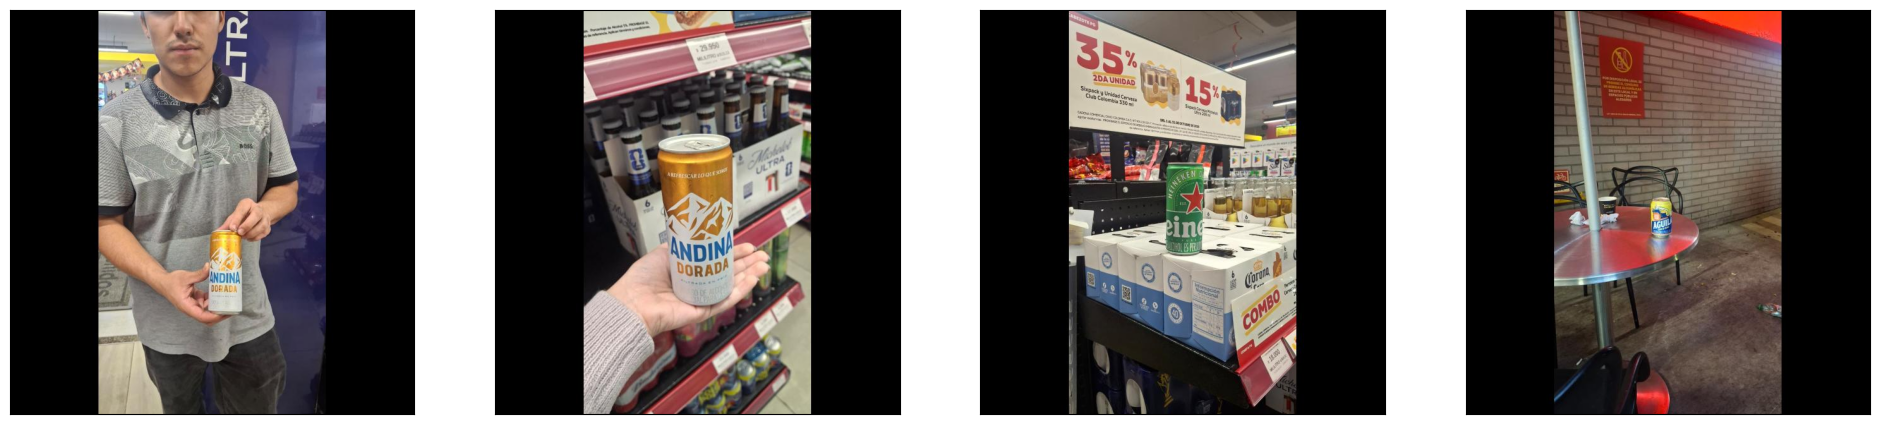

In [7]:
plt.figure(figsize=(24, 6))
for i, imgP in enumerate(image_paths[0:4]):
    ax = plt.subplot(1, 4, i + 1)
    plt.imshow(plt.imread(imgP))
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

## 4. El archivo `data.yaml` y sus rutas (la parte de "cambiar los dos puntos")
`data.yaml` le dice a YOLO **dónde están las imágenes** (`train`, `val`, `test`), **cuántas clases hay** (`nc`) y
**cómo se llaman** (`names`). Roboflow lo genera con rutas **relativas** como `../train/images`.

**El problema:** `..` significa "la carpeta de arriba" **respecto a la carpeta desde donde se ejecuta**. Si YOLO no
corre exactamente desde ahí, no encuentra las imágenes y el entrenamiento falla.

**La solución de clase:** cambiar los `..` por la **ruta completa** de cada carpeta. La celda siguiente lo hace sola:
1. Guarda una copia del original como `data_original.yaml`.
2. Reemplaza `train`, `val` y `test` por rutas completas.
3. Muestra el antes y el después.

In [8]:
DATA_YAML = DATASET_DIR / "data.yaml"
copia = DATASET_DIR / "data_original.yaml"
if not copia.exists():
    shutil.copy(DATA_YAML, copia)

print("ANTES:\n" + copia.read_text(encoding="utf-8"))

with open(copia, encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

data_cfg["train"] = str((DATASET_DIR / "train" / "images").resolve())
data_cfg["val"] = str((DATASET_DIR / "valid" / "images").resolve())
if (DATASET_DIR / "test" / "images").exists():
    data_cfg["test"] = str((DATASET_DIR / "test" / "images").resolve())
data_cfg.pop("path", None)

with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(data_cfg, f, allow_unicode=True, sort_keys=False)

print("DESPUÉS:\n" + DATA_YAML.read_text(encoding="utf-8"))

num_classes = data_cfg["nc"]
CLASES = list(data_cfg["names"].values()) if isinstance(data_cfg["names"], dict) else list(data_cfg["names"])
TIENE_TEST = "test" in data_cfg
print(num_classes, "clases:", CLASES)

ANTES:
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 6
names: ['aguila', 'andina', 'club_colombia', 'costena', 'heineken', 'poker']

roboflow:
  workspace: ia-8qlm8
  project: cervezas-nao
  version: 4
  license: Private
  url: https://app.roboflow.com/ia-8qlm8/cervezas-nao/4
DESPUÉS:
train: C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\train\images
val: C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\valid\images
test: C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\test\images
nc: 6
names:
- aguila
- andina
- club_colombia
- costena
- heineken
- poker
roboflow:
  workspace: ia-8qlm8
  project: cervezas-nao
  version: 4
  license: Private
  url: https://app.roboflow.com/ia-8qlm8/cervezas-

### Revisión rápida del dataset
Cuántas cajas hay de cada marca, cuántas imágenes de **fondo** (sin cajas) y el tamaño mínimo. Con 60 fotos los
números son pequeños, sobre todo en `valid` y `test`: las métricas de este primer intento varían mucho con pocas
imágenes. Tómenlas como una primera señal, no como el resultado final.

In [9]:
from collections import Counter

print(f"{'split':<7}{'imágenes':>9}{'fondo':>7}  cajas por clase")
for split in ["train", "valid", "test"]:
    imgs = sorted(p for e in EXT for p in (DATASET_DIR / split / "images").glob(e))
    if not imgs:
        continue
    conteo, fondos, minimo = Counter(), 0, 10**9
    for p in imgs:
        lbl = DATASET_DIR / split / "labels" / (p.stem + ".txt")
        lineas = [l for l in lbl.read_text().splitlines() if l.strip()] if lbl.exists() else []
        fondos += not lineas
        conteo.update(CLASES[int(l.split()[0])] for l in lineas)
        with Image.open(p) as im:
            minimo = min(minimo, min(im.size))
    print(f"{split:<7}{len(imgs):>9}{fondos:>7}  {dict(conteo)}  (lado mínimo: {minimo} px)")

split   imágenes  fondo  cajas por clase
train         77      5  {'andina': 17, 'heineken': 18, 'aguila': 17, 'club_colombia': 28, 'poker': 24, 'costena': 19}  (lado mínimo: 640 px)
valid         22      2  {'heineken': 9, 'aguila': 7, 'andina': 8, 'club_colombia': 7, 'poker': 7, 'costena': 7}  (lado mínimo: 640 px)
test          11      0  {'andina': 1, 'heineken': 3, 'poker': 4, 'aguila': 2, 'club_colombia': 5, 'costena': 6}  (lado mínimo: 640 px)


## 5. Modelo 1 — YOLO26 **nano** (el más rápido)
Igual que en clase con `yolo26m.pt`, pero con el tamaño **n**. Se parte de un modelo **preentrenado con COCO**
(*transfer learning*): conserva lo que ya sabe "ver" (bordes, formas, colores) y aprende solo nuestras 6 marcas.

Parámetros, como en clase:
- `data` = nuestro `data.yaml` corregido.
- `epochs` = número de pasadas por todas las imágenes.
- `imgsz` = tamaño de entrada.
- `project` / `name` = dónde se guarda todo (`path/subpath`): pesos `weights/best.pt` y `weights/last.pt`, gráficas y
  `results.csv`. **Así se van guardando los modelos.**

Dos parámetros extra:
- `patience`: para solo si deja de mejorar.
- `fliplr=0.0`: **no voltear** las imágenes, porque voltear una lata deja el logo y las letras al revés.

**Sin cambios previos a las imágenes:** el aumento de datos lo hace YOLO solo durante el entrenamiento (mosaico,
color, escala) y ajusta las cajas automáticamente.

In [10]:
# (Opcional, como en clase) gráficas en vivo con TensorBoard: requiere "pip install tensorboard"
# from ultralytics import settings
# settings.update({"tensorboard": True})

In [11]:
model_nano = YOLO("yolo26n.pt")
results_nano = model_nano.train(data=str(DATA_YAML), epochs=EPOCAS, imgsz=IMGSZ,
                                project=str(path),     # dirección para guardar los resultados
                                name=subpath_nano,     # nombre del subdirectorio
                                val=True, patience=PACIENCIA, batch=BATCH, workers=WORKERS,
                                device=DEVICE, fliplr=0.0, seed=0)
RUN_NANO = Path(model_nano.trainer.save_dir)
print("Guardado en:", RUN_NANO)

Ultralytics 8.4.196  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=nano_v4, nbs=64, nms=N

Overriding model.yaml nc=80 with nc=6



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (1,691 outputs left out)

                 poker          7          7          1      0.921      0.995       0.95


Speed: 0.2ms preprocess, 3.3ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\nano_v4


Guardado en: C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\nano_v4


### Evaluar el entrenamiento
- **`results.png`:** pérdidas de entrenamiento y validación por época, y métricas. Las pérdidas deben **bajar**. Si la
  de validación sube mientras la de entrenamiento baja, hay **sobreajuste**, un riesgo real con pocas fotos.
- **`train_batch0.jpg`:** un lote de entrenamiento con sus etiquetas. Sirve para revisar que las cajas estén bien
  puestas.

results.png


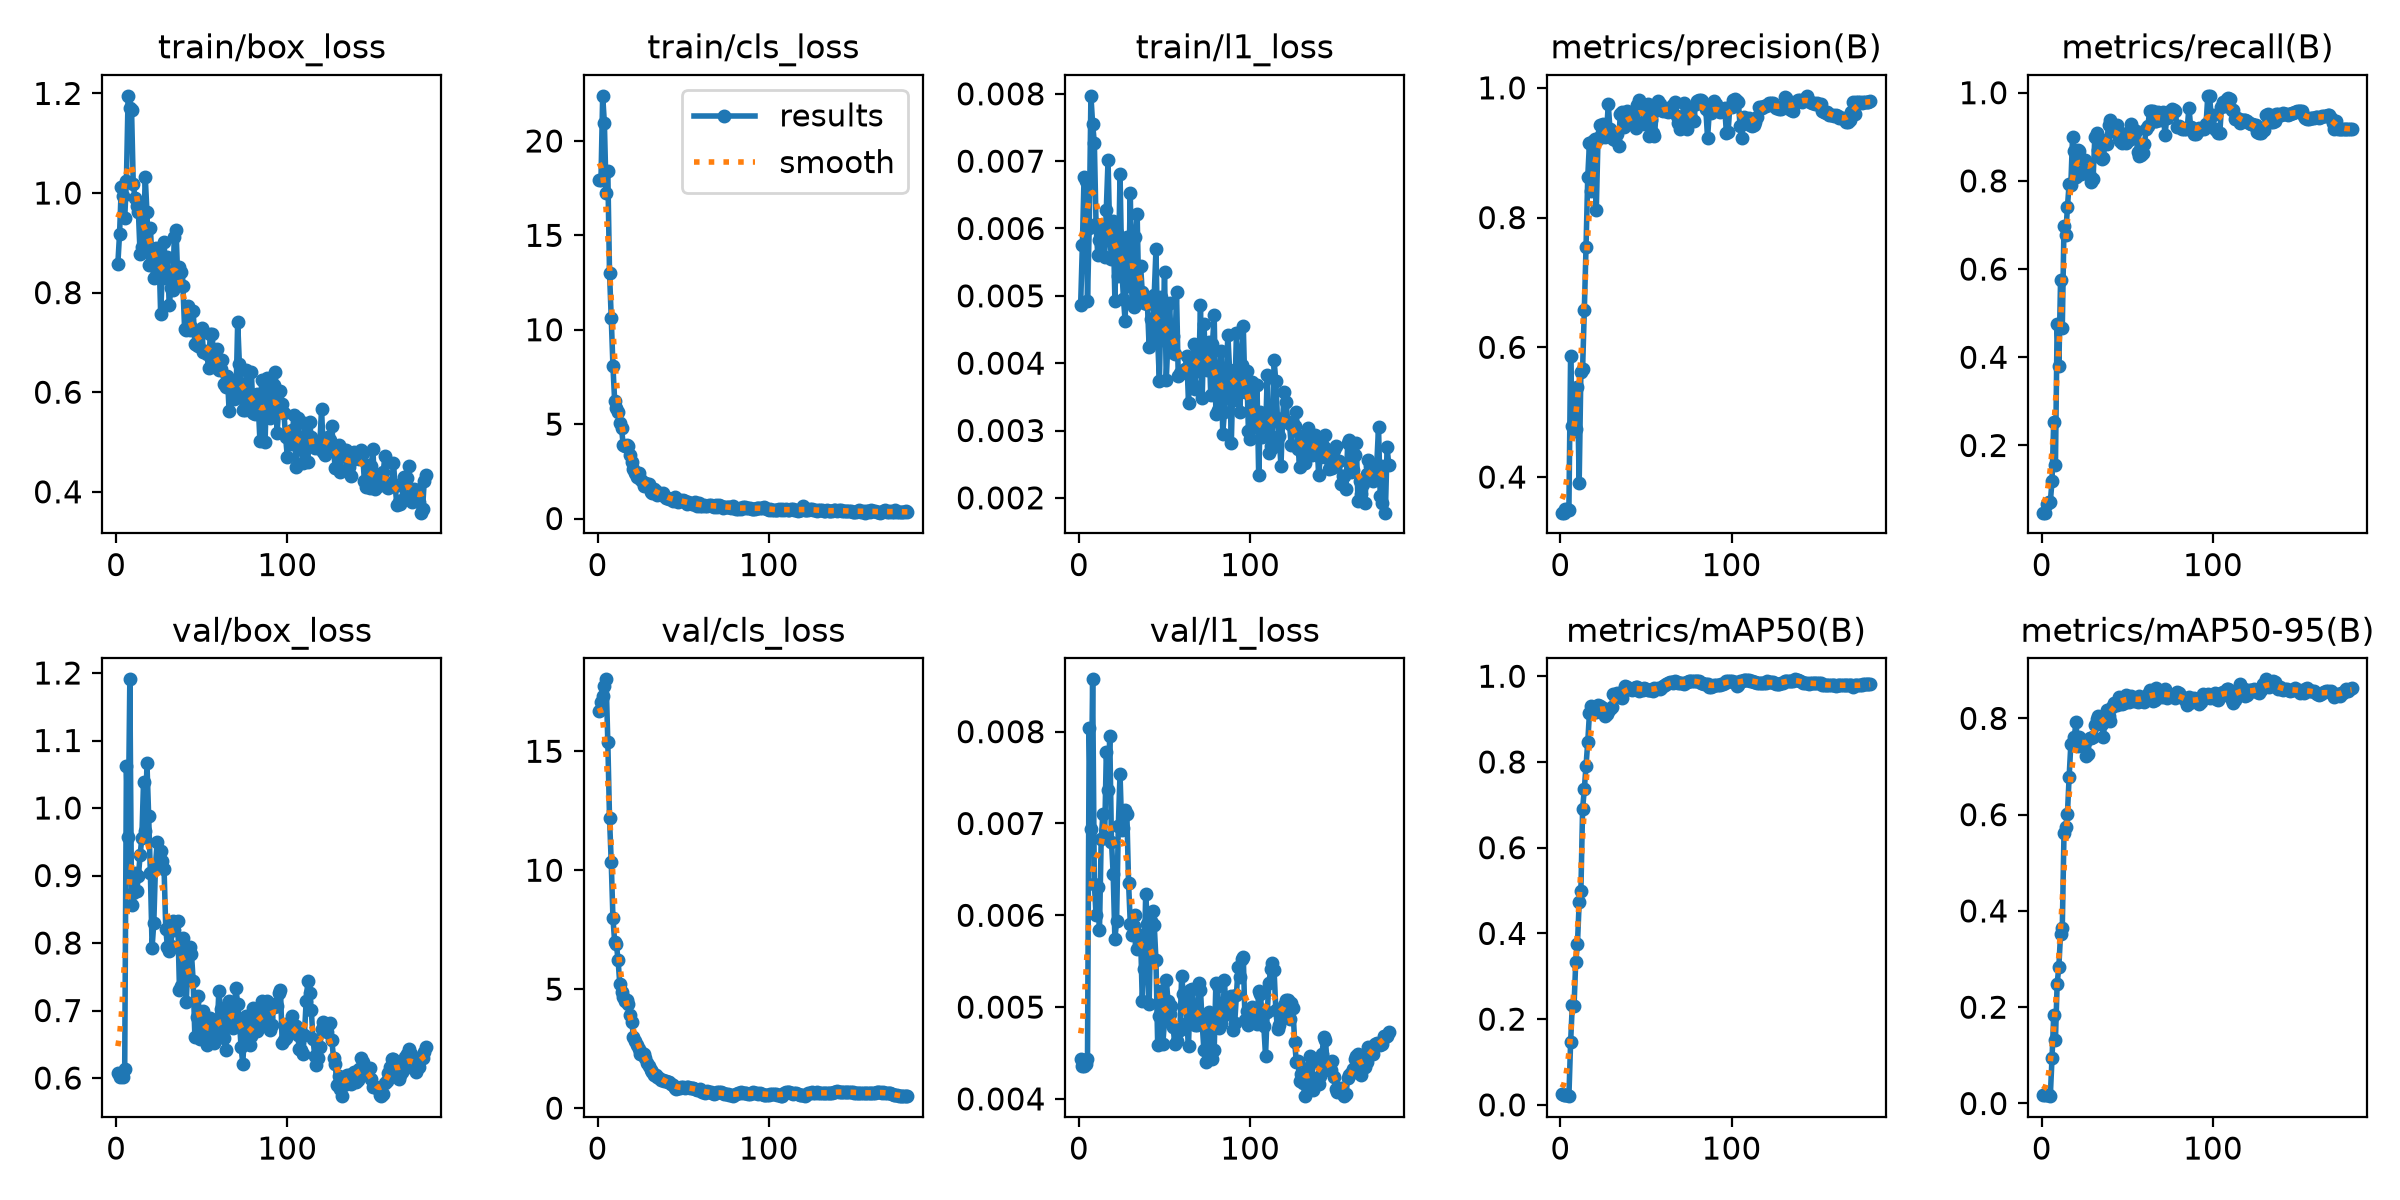

['args.yaml', 'BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'labels.jpg', 'results.csv', 'results.png', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'weights']


In [12]:
mostrar(RUN_NANO / "results.png", 1000)
print(os.listdir(RUN_NANO))

train_batch0.jpg


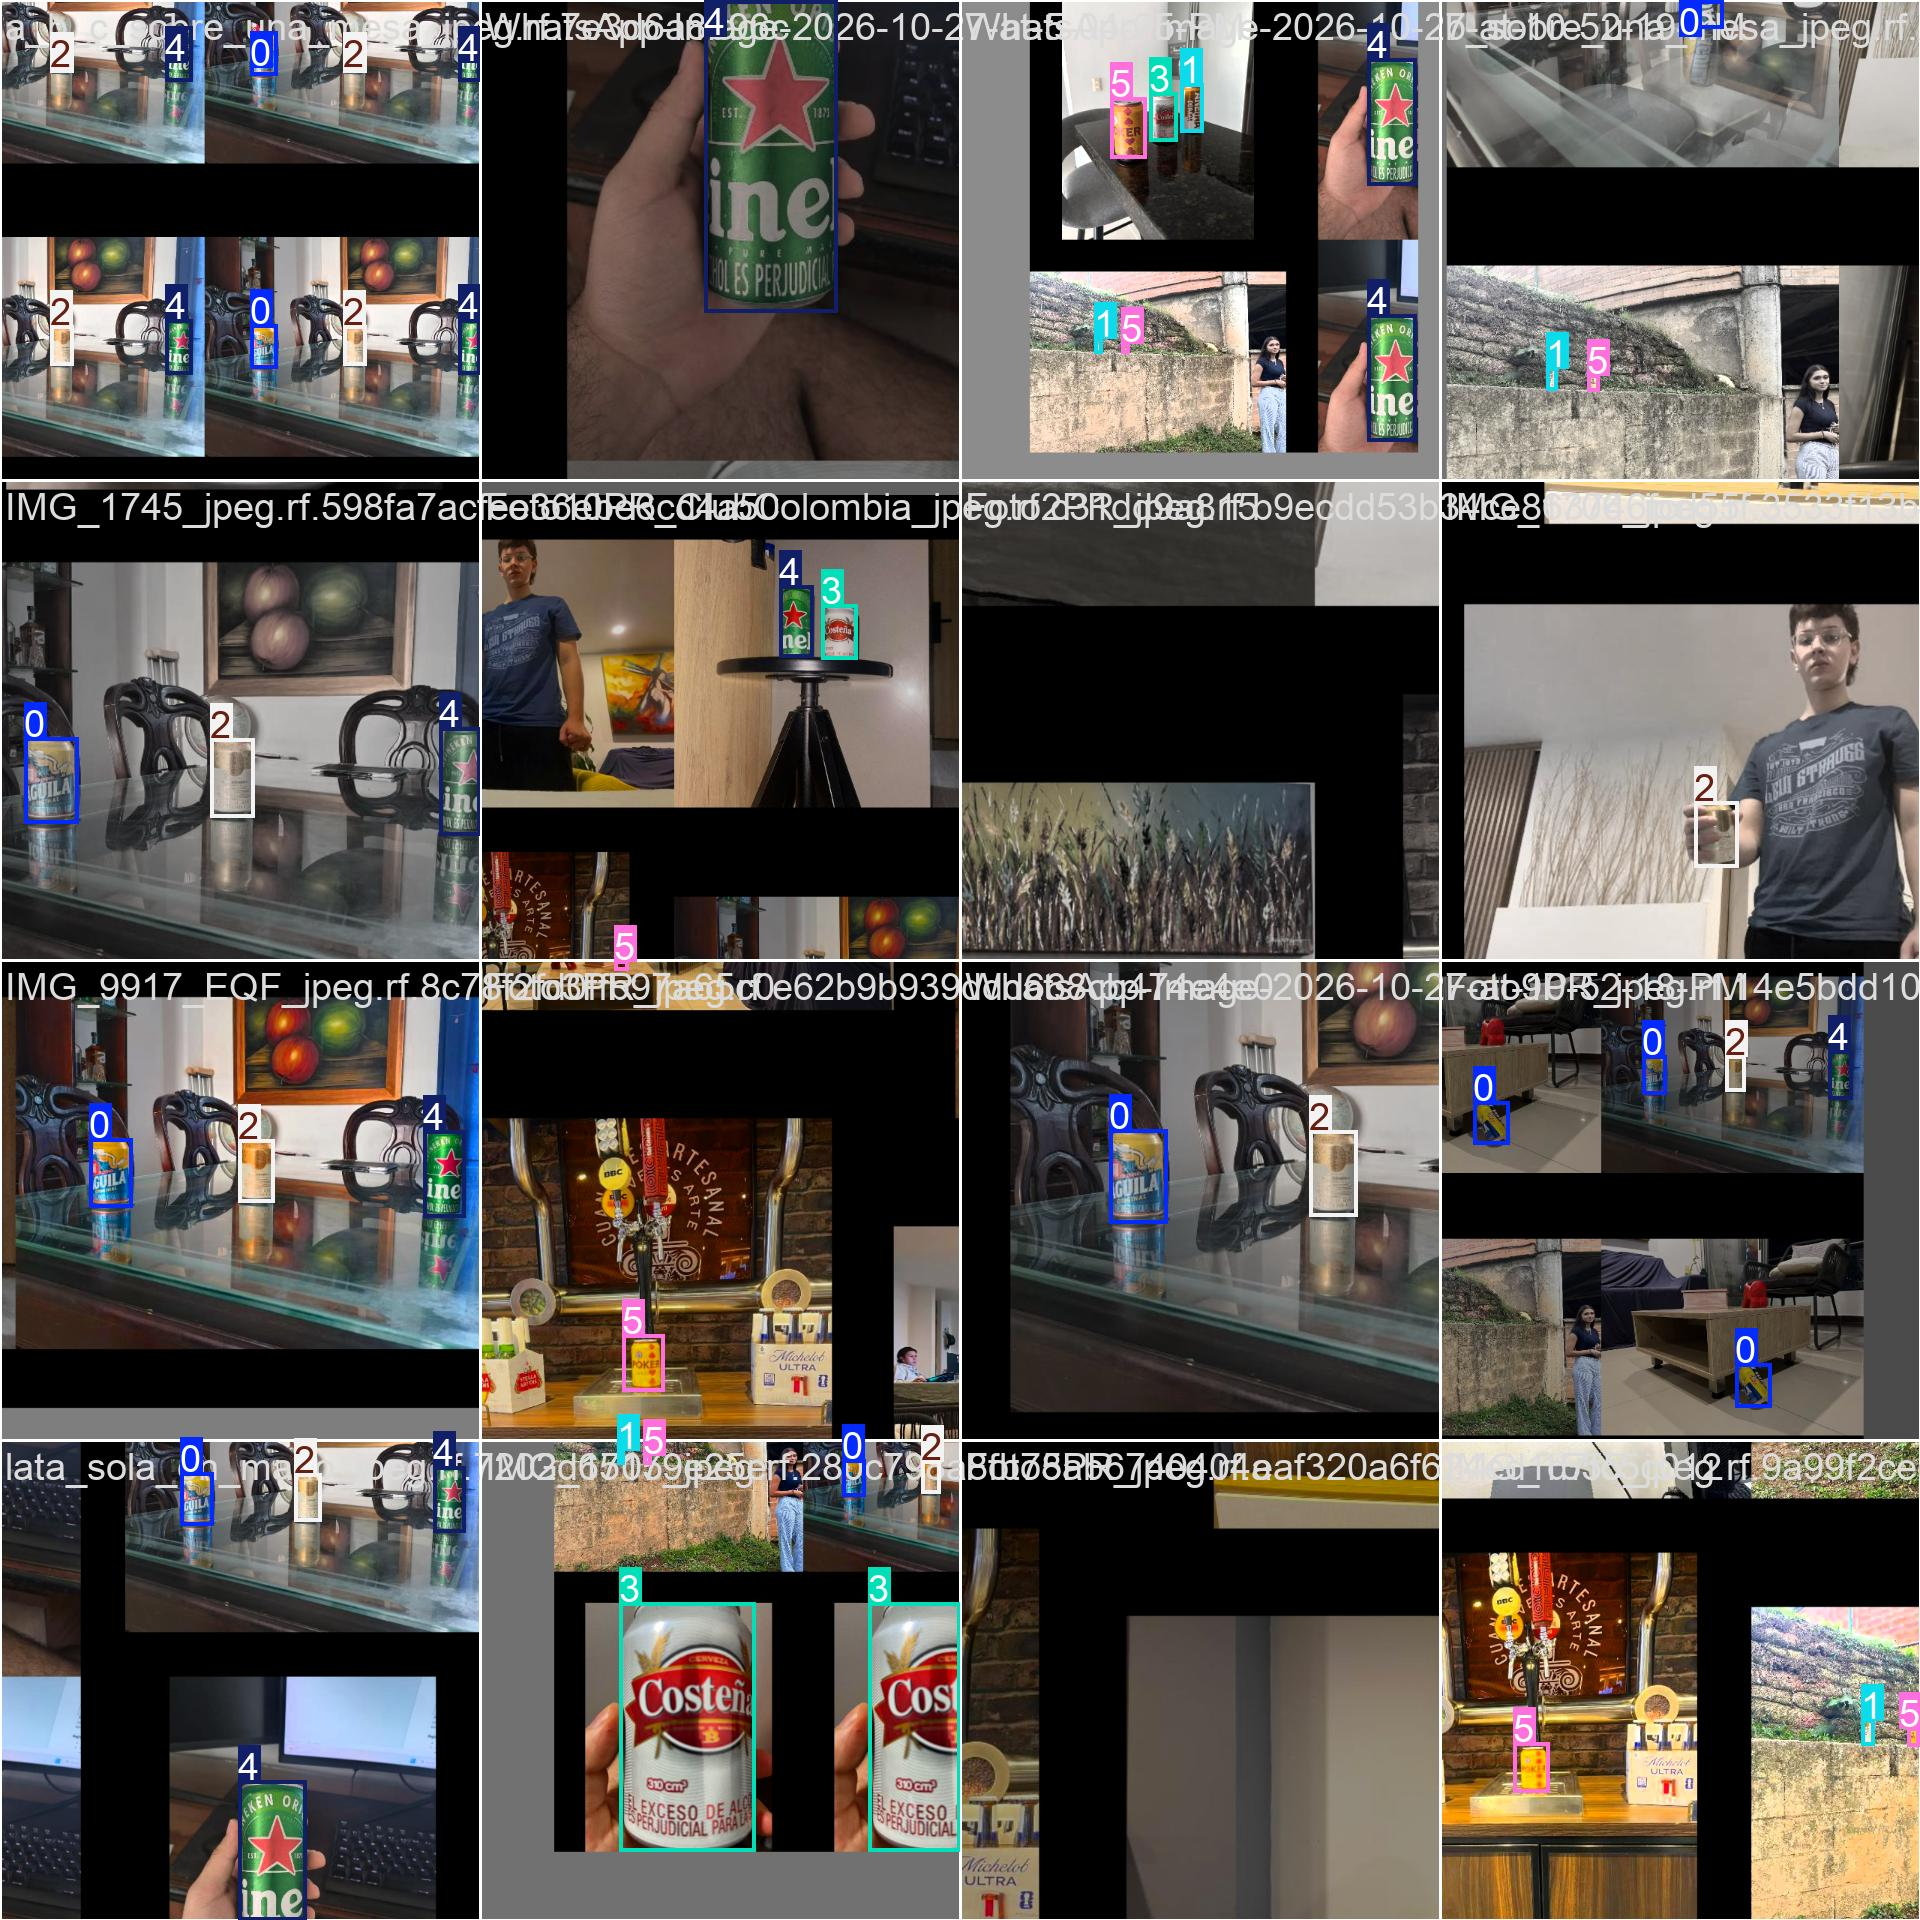

In [13]:
mostrar(RUN_NANO / "train_batch0.jpg", 1000)

### Validar el modelo (con `best.pt`)
Como en clase: se carga el **mejor** modelo y se ejecuta `model.val()`.
- `map` = mAP50-95 (exigente): promedia IoU de 0.50 a 0.95.
- `map50` = mAP con IoU ≥ 0.5 (permisivo).
- `map75` = mAP con IoU ≥ 0.75.
- `maps` = mAP50-95 de cada clase.

**IoU** = área de intersección / área de unión entre la caja predicha y la real. Si mAP50-95 es mucho menor que
mAP50, el modelo detecta bien pero ajusta mal las cajas.

In [14]:
def resumen(metrics, titulo):
    b = metrics.box
    print(f"=== {titulo} ===")
    print(f"P {b.mp:.3f} | R {b.mr:.3f} | mAP50 {b.map50:.3f} | mAP50-95 {b.map:.3f} | mAP75 {b.map75:.3f}")
    for j, c in enumerate(b.ap_class_index):
        print(f"  {CLASES[int(c)]:<15} P {b.p[j]:.2f}  R {b.r[j]:.2f}  mAP50 {b.ap50[j]:.2f}  mAP50-95 {b.ap[j]:.2f}")

best_nano = YOLO(RUN_NANO / "weights" / "best.pt")
metrics_nano = best_nano.val(data=str(DATA_YAML), split="val", imgsz=IMGSZ, device=DEVICE, plots=True,
                             project=str(RUN_NANO), name="val", exist_ok=True)
print(metrics_nano.box.map)    # mAP50-95
print(metrics_nano.box.map50)  # mAP50
print(metrics_nano.box.map75)  # mAP75
print(metrics_nano.box.maps)   # mAP50-95 por clase
resumen(metrics_nano, "NANO - validación")

Ultralytics 8.4.196  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 488.7±121.8 MB/s, size: 38.1 KB)


val: Scanning C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\valid\labels.cache... 22 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 9.2s/it 2.8s<9.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.5s/it 3.0s

... (6 outputs left out)

                 poker          7          7          1      0.921      0.995       0.95


Speed: 5.1ms preprocess, 18.7ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\nano_v4\val


0.88407408008658
0.9895454545454546
0.9877121212121213
[     0.9095     0.81444     0.82345       0.901     0.90606        0.95]
=== NANO - validación ===
P 0.985 | R 0.949 | mAP50 0.990 | mAP50-95 0.884 | mAP75 0.988
  aguila          P 1.00  R 0.93  mAP50 0.99  mAP50-95 0.91
  andina          P 0.95  R 0.88  mAP50 0.96  mAP50-95 0.81
  club_colombia   P 0.97  R 1.00  mAP50 0.99  mAP50-95 0.82
  costena         P 1.00  R 0.97  mAP50 0.99  mAP50-95 0.90
  heineken        P 0.99  R 1.00  mAP50 0.99  mAP50-95 0.91
  poker           P 1.00  R 0.92  mAP50 0.99  mAP50-95 0.95


### Etiquetas reales vs. predicciones, y matriz de confusión
- `val_batch0_labels.jpg` (lo real) contra `val_batch0_pred.jpg` (lo que predijo el modelo).
- **Matriz de confusión:** eje X = clase **real**, eje Y = clase **predicha**; la diagonal son los aciertos.
  - Fila *background*: latas que **no detectó** (falsos negativos).
  - Columna *background*: detectó una lata **donde no había nada** (falsos positivos).
  - Fuera de la diagonal: confundió una marca con otra (por ejemplo, Águila ↔ Club Colombia).

val_batch0_labels.jpg


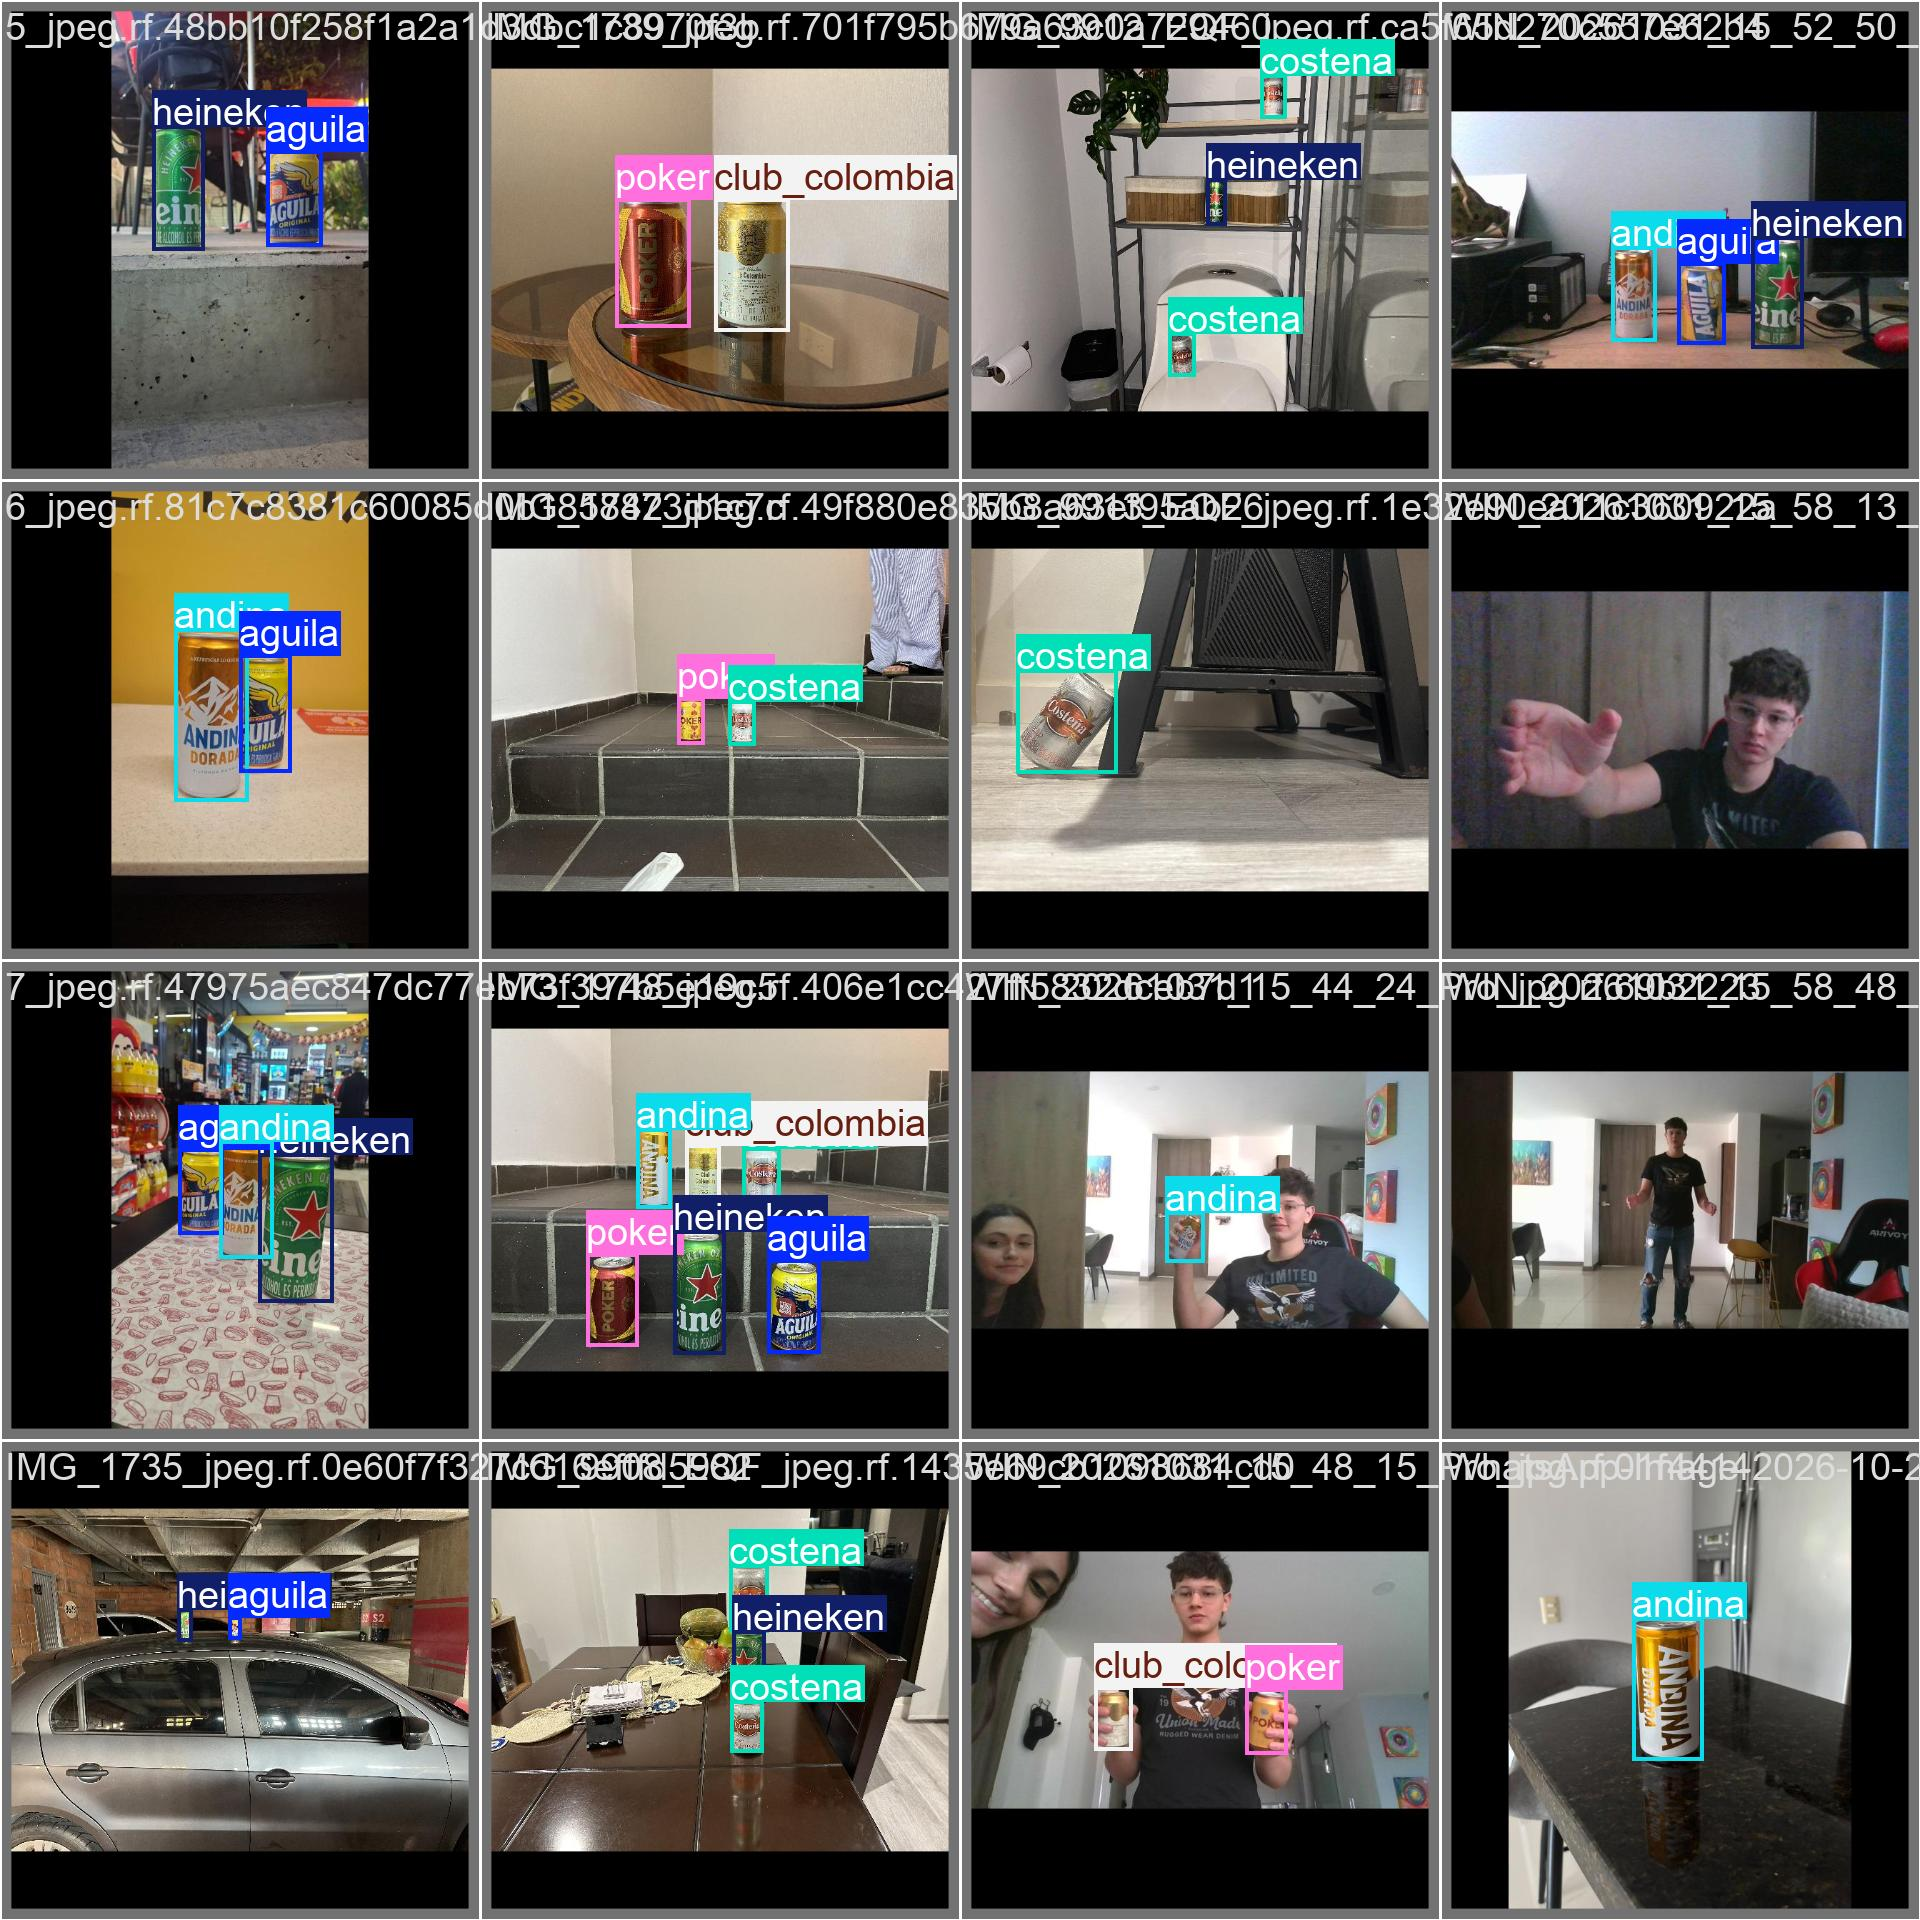

val_batch0_pred.jpg


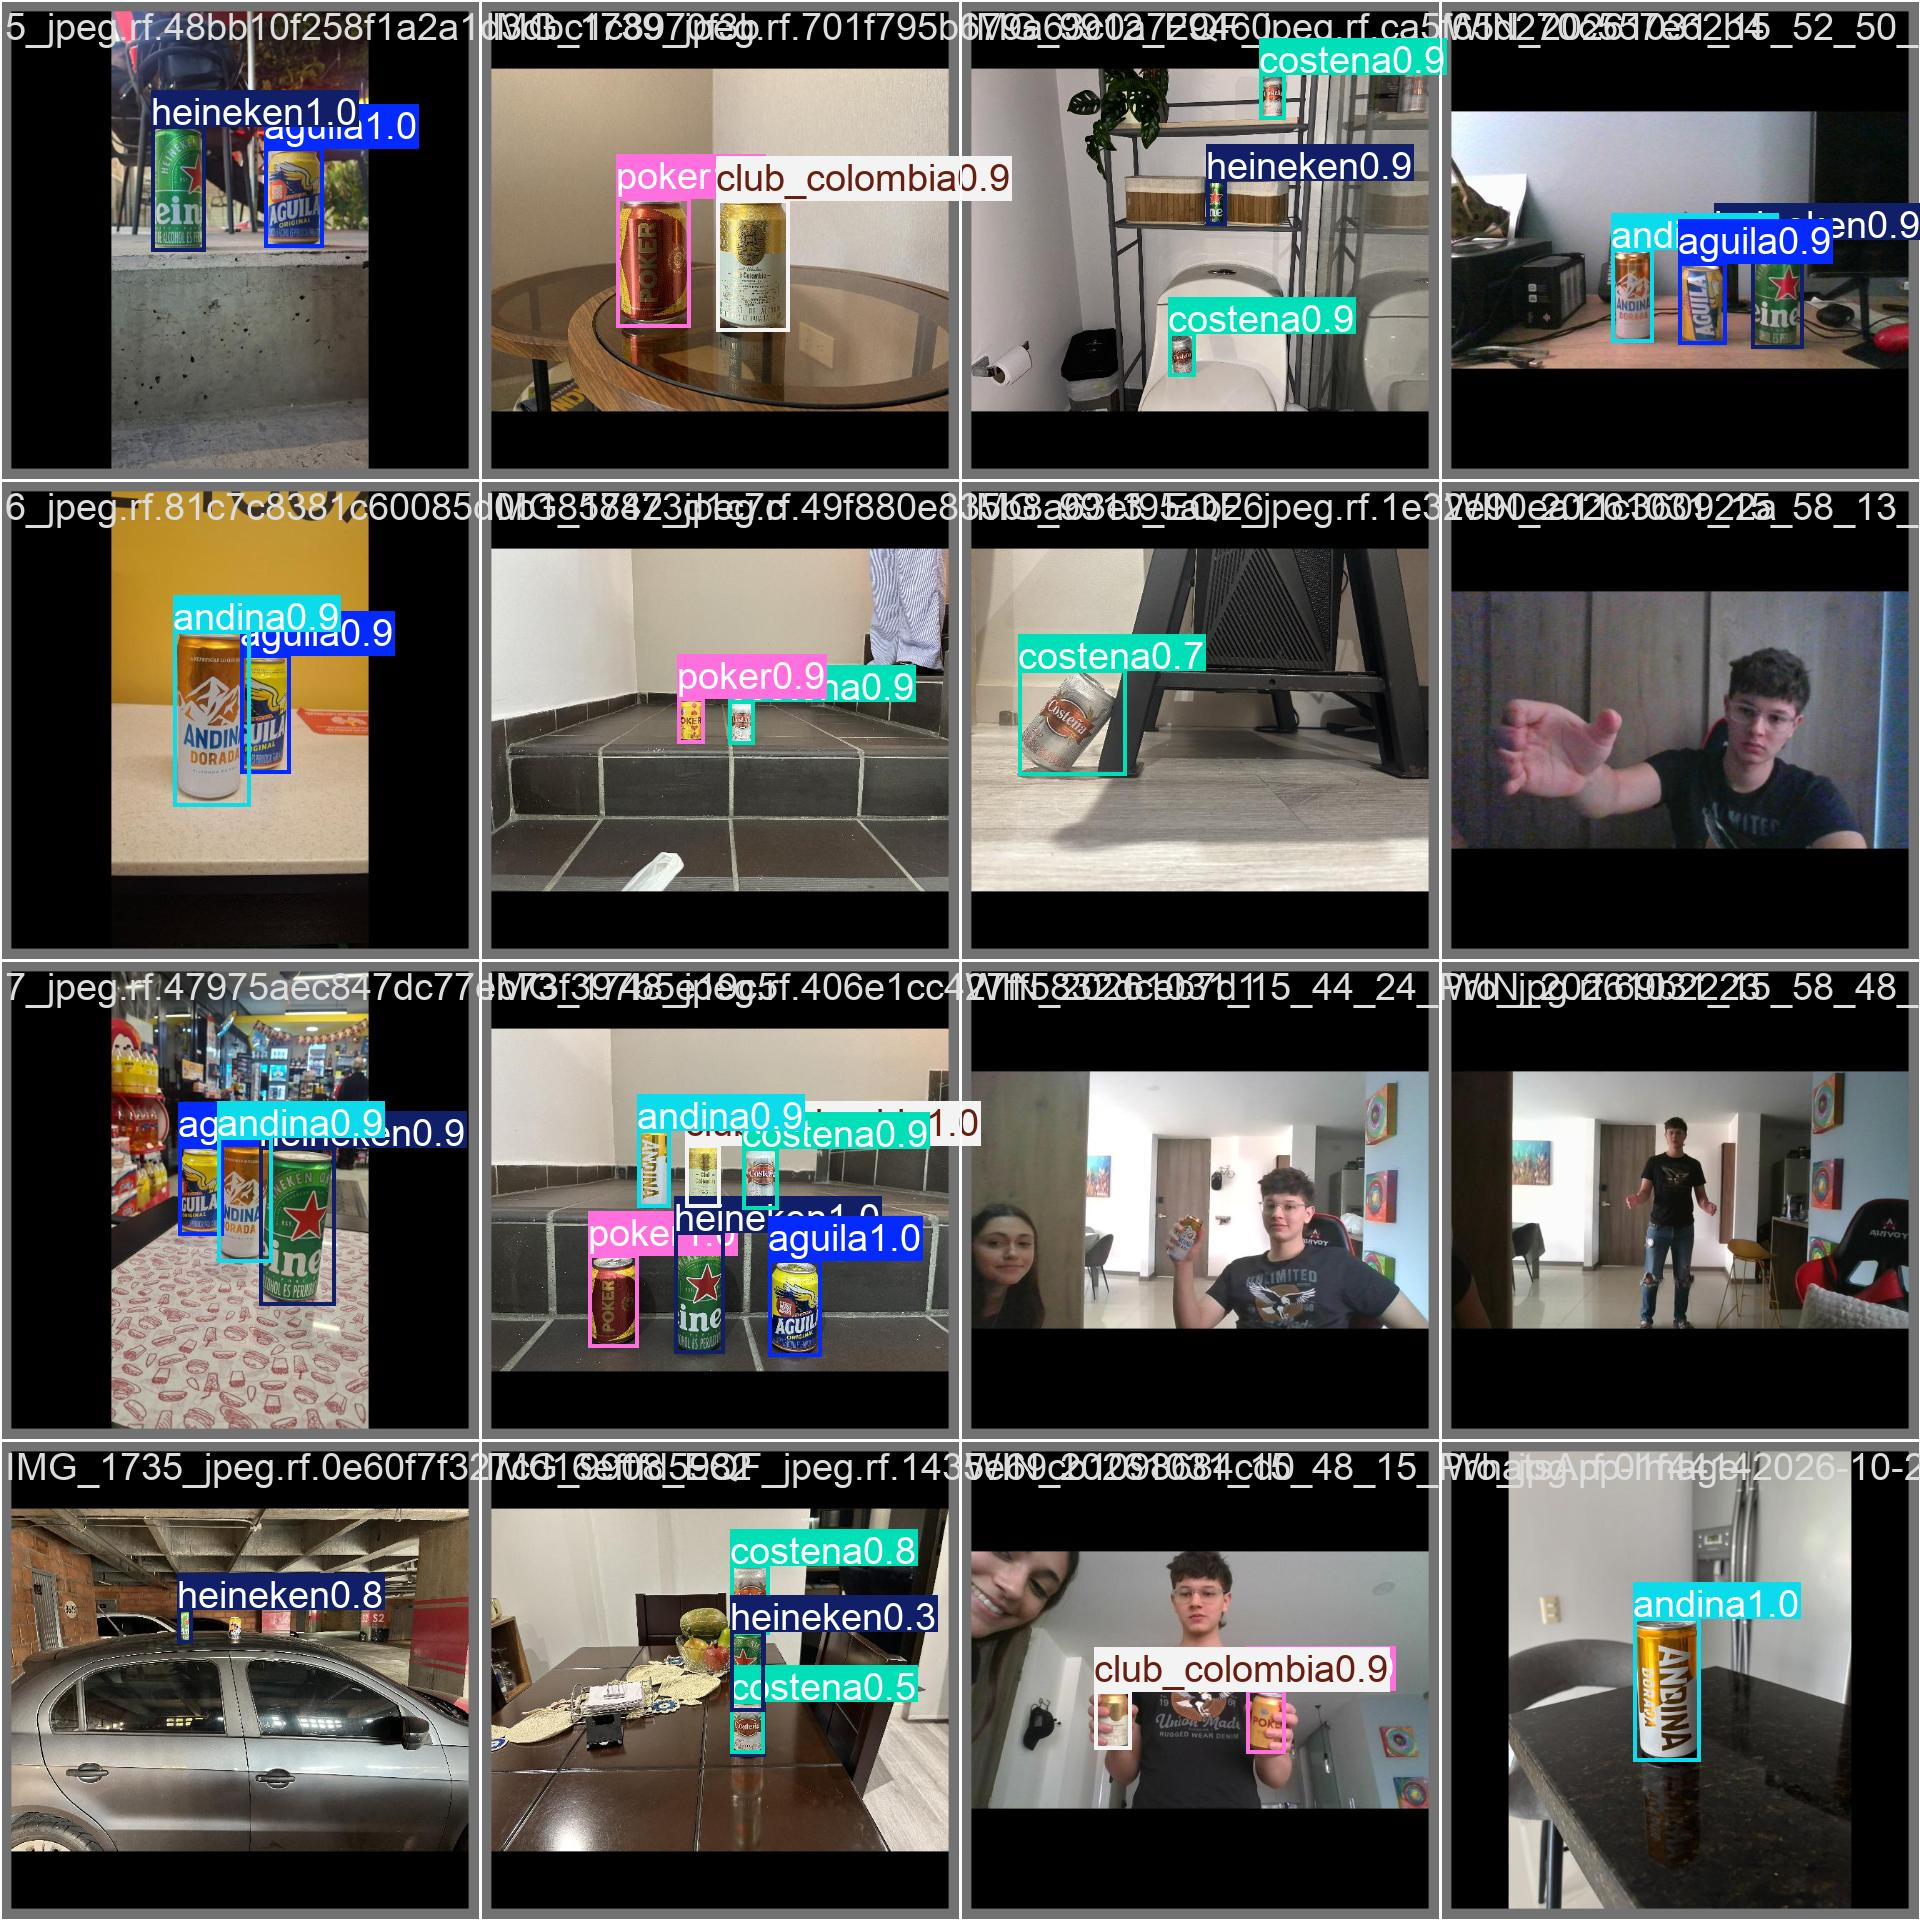

In [15]:
mostrar(RUN_NANO / "val" / "val_batch0_labels.jpg", 800)
mostrar(RUN_NANO / "val" / "val_batch0_pred.jpg", 800)

confusion_matrix.png


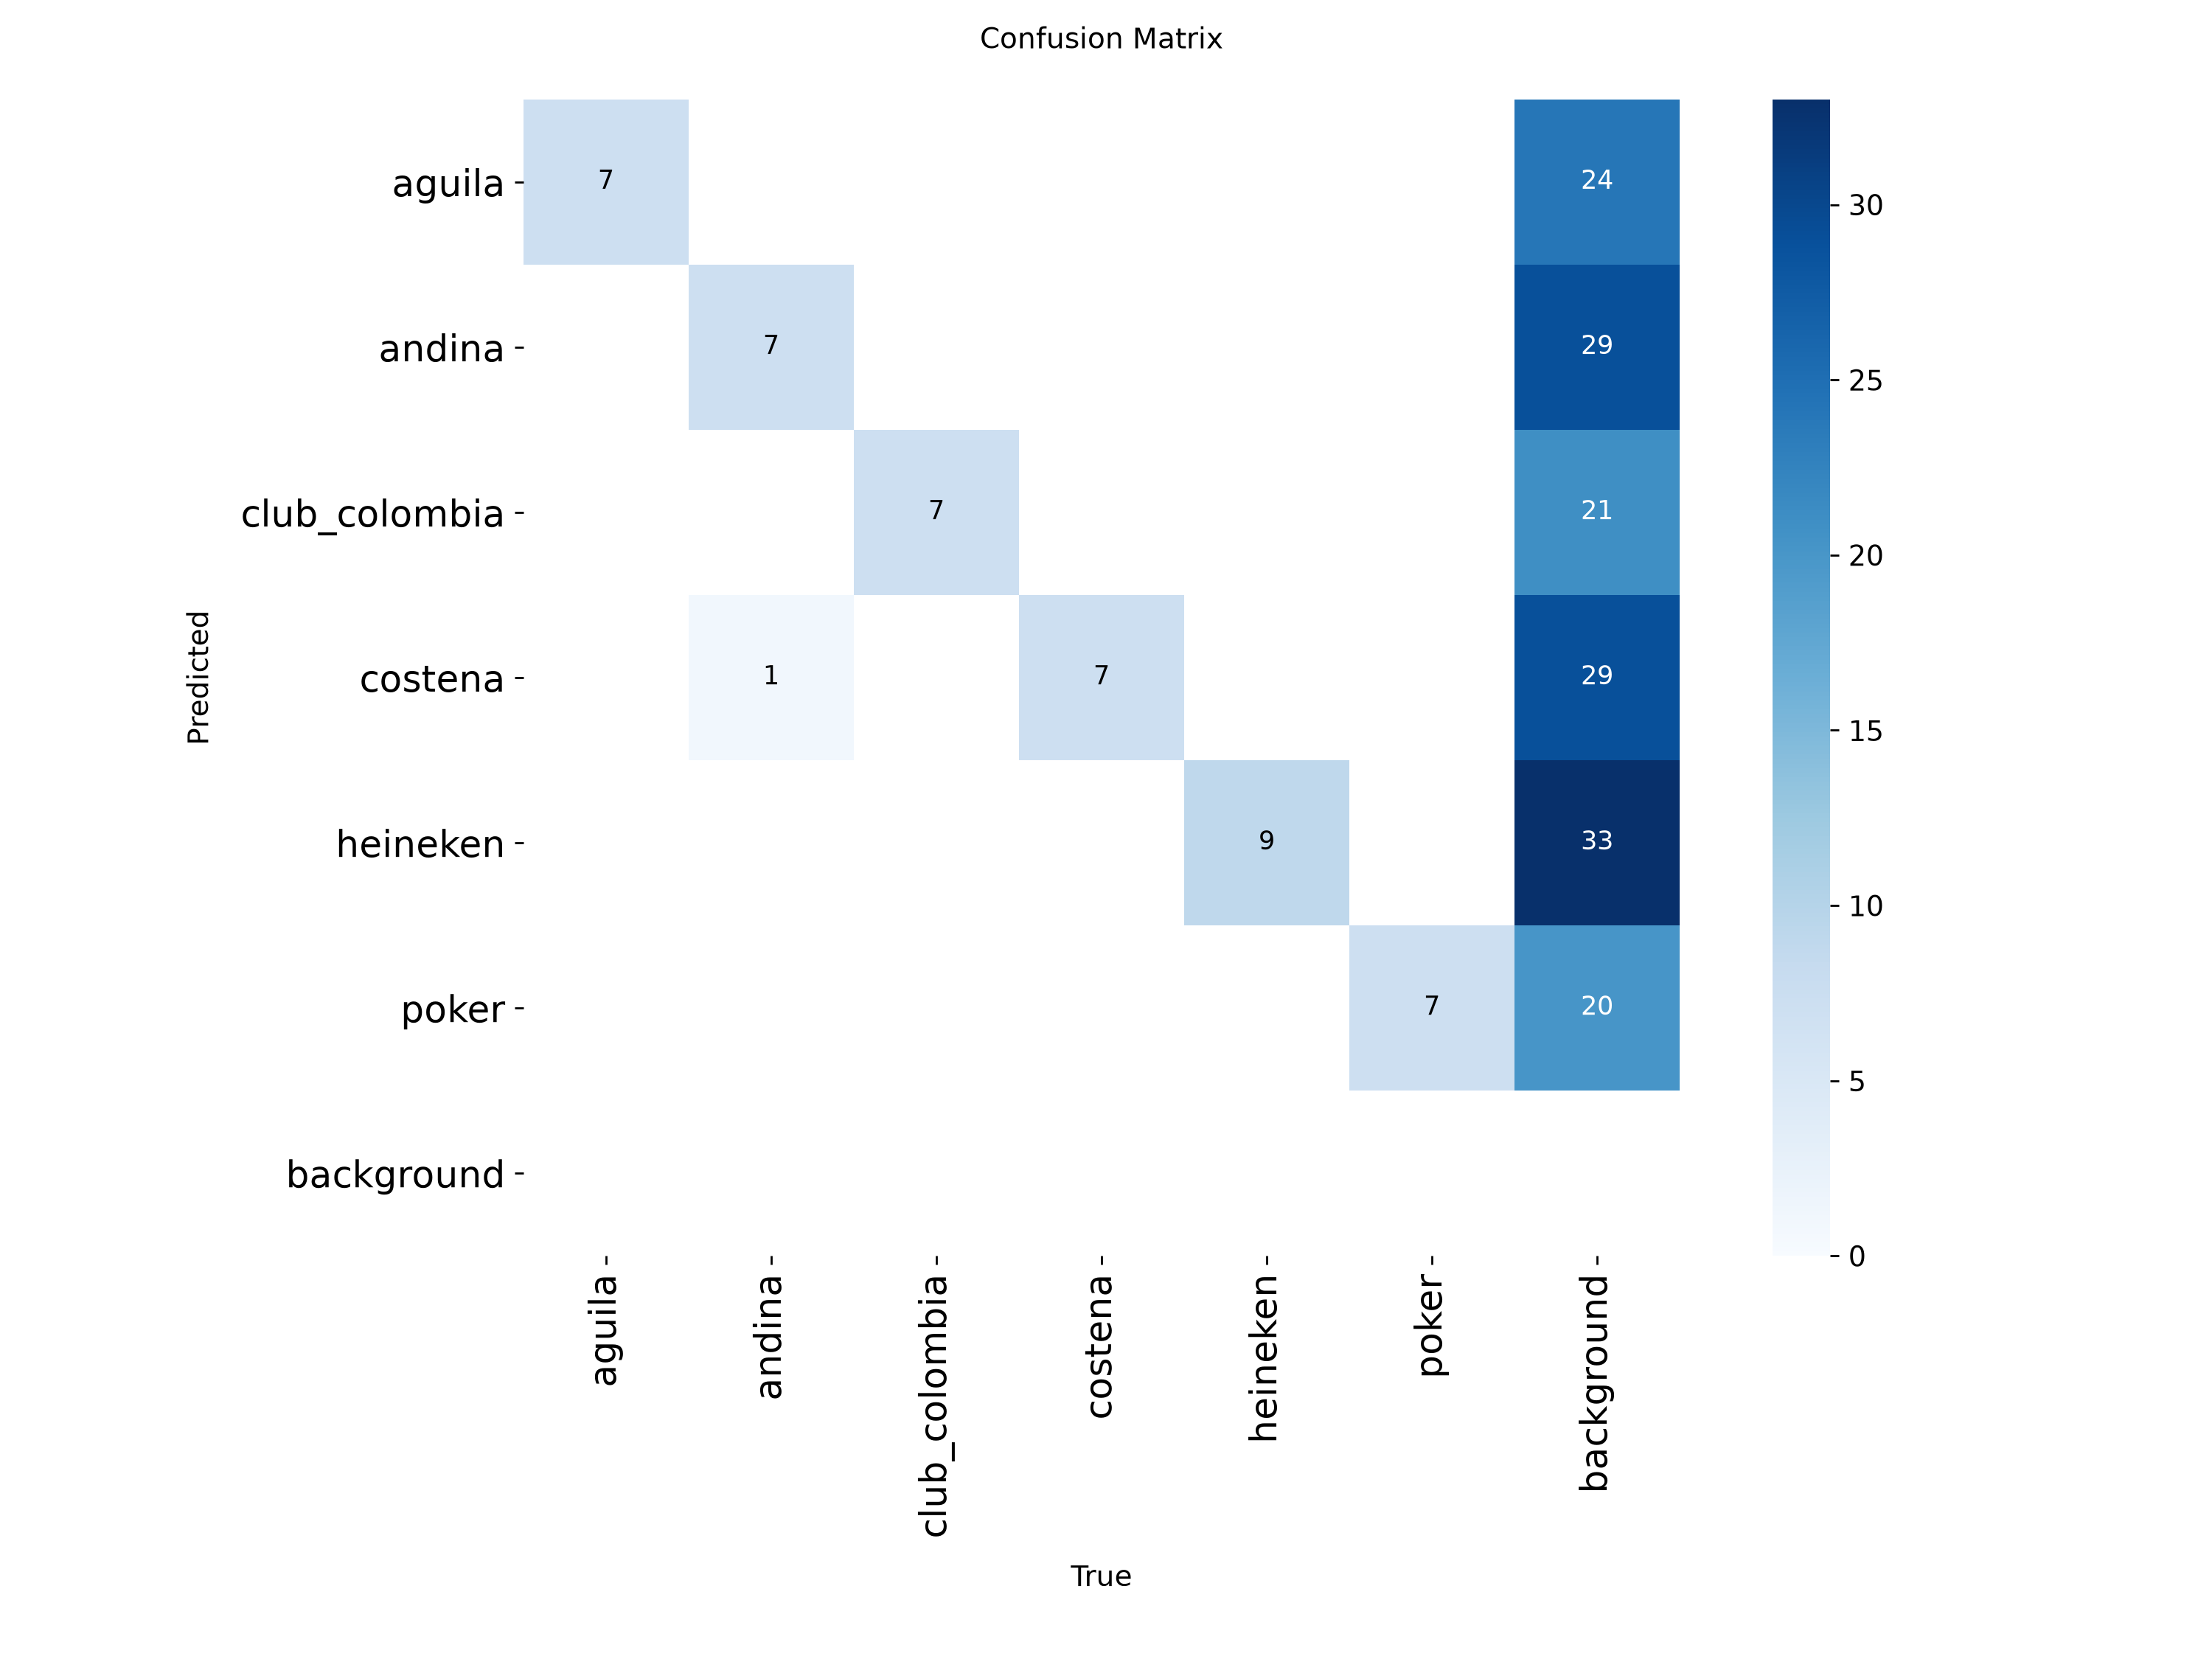

confusion_matrix_normalized.png


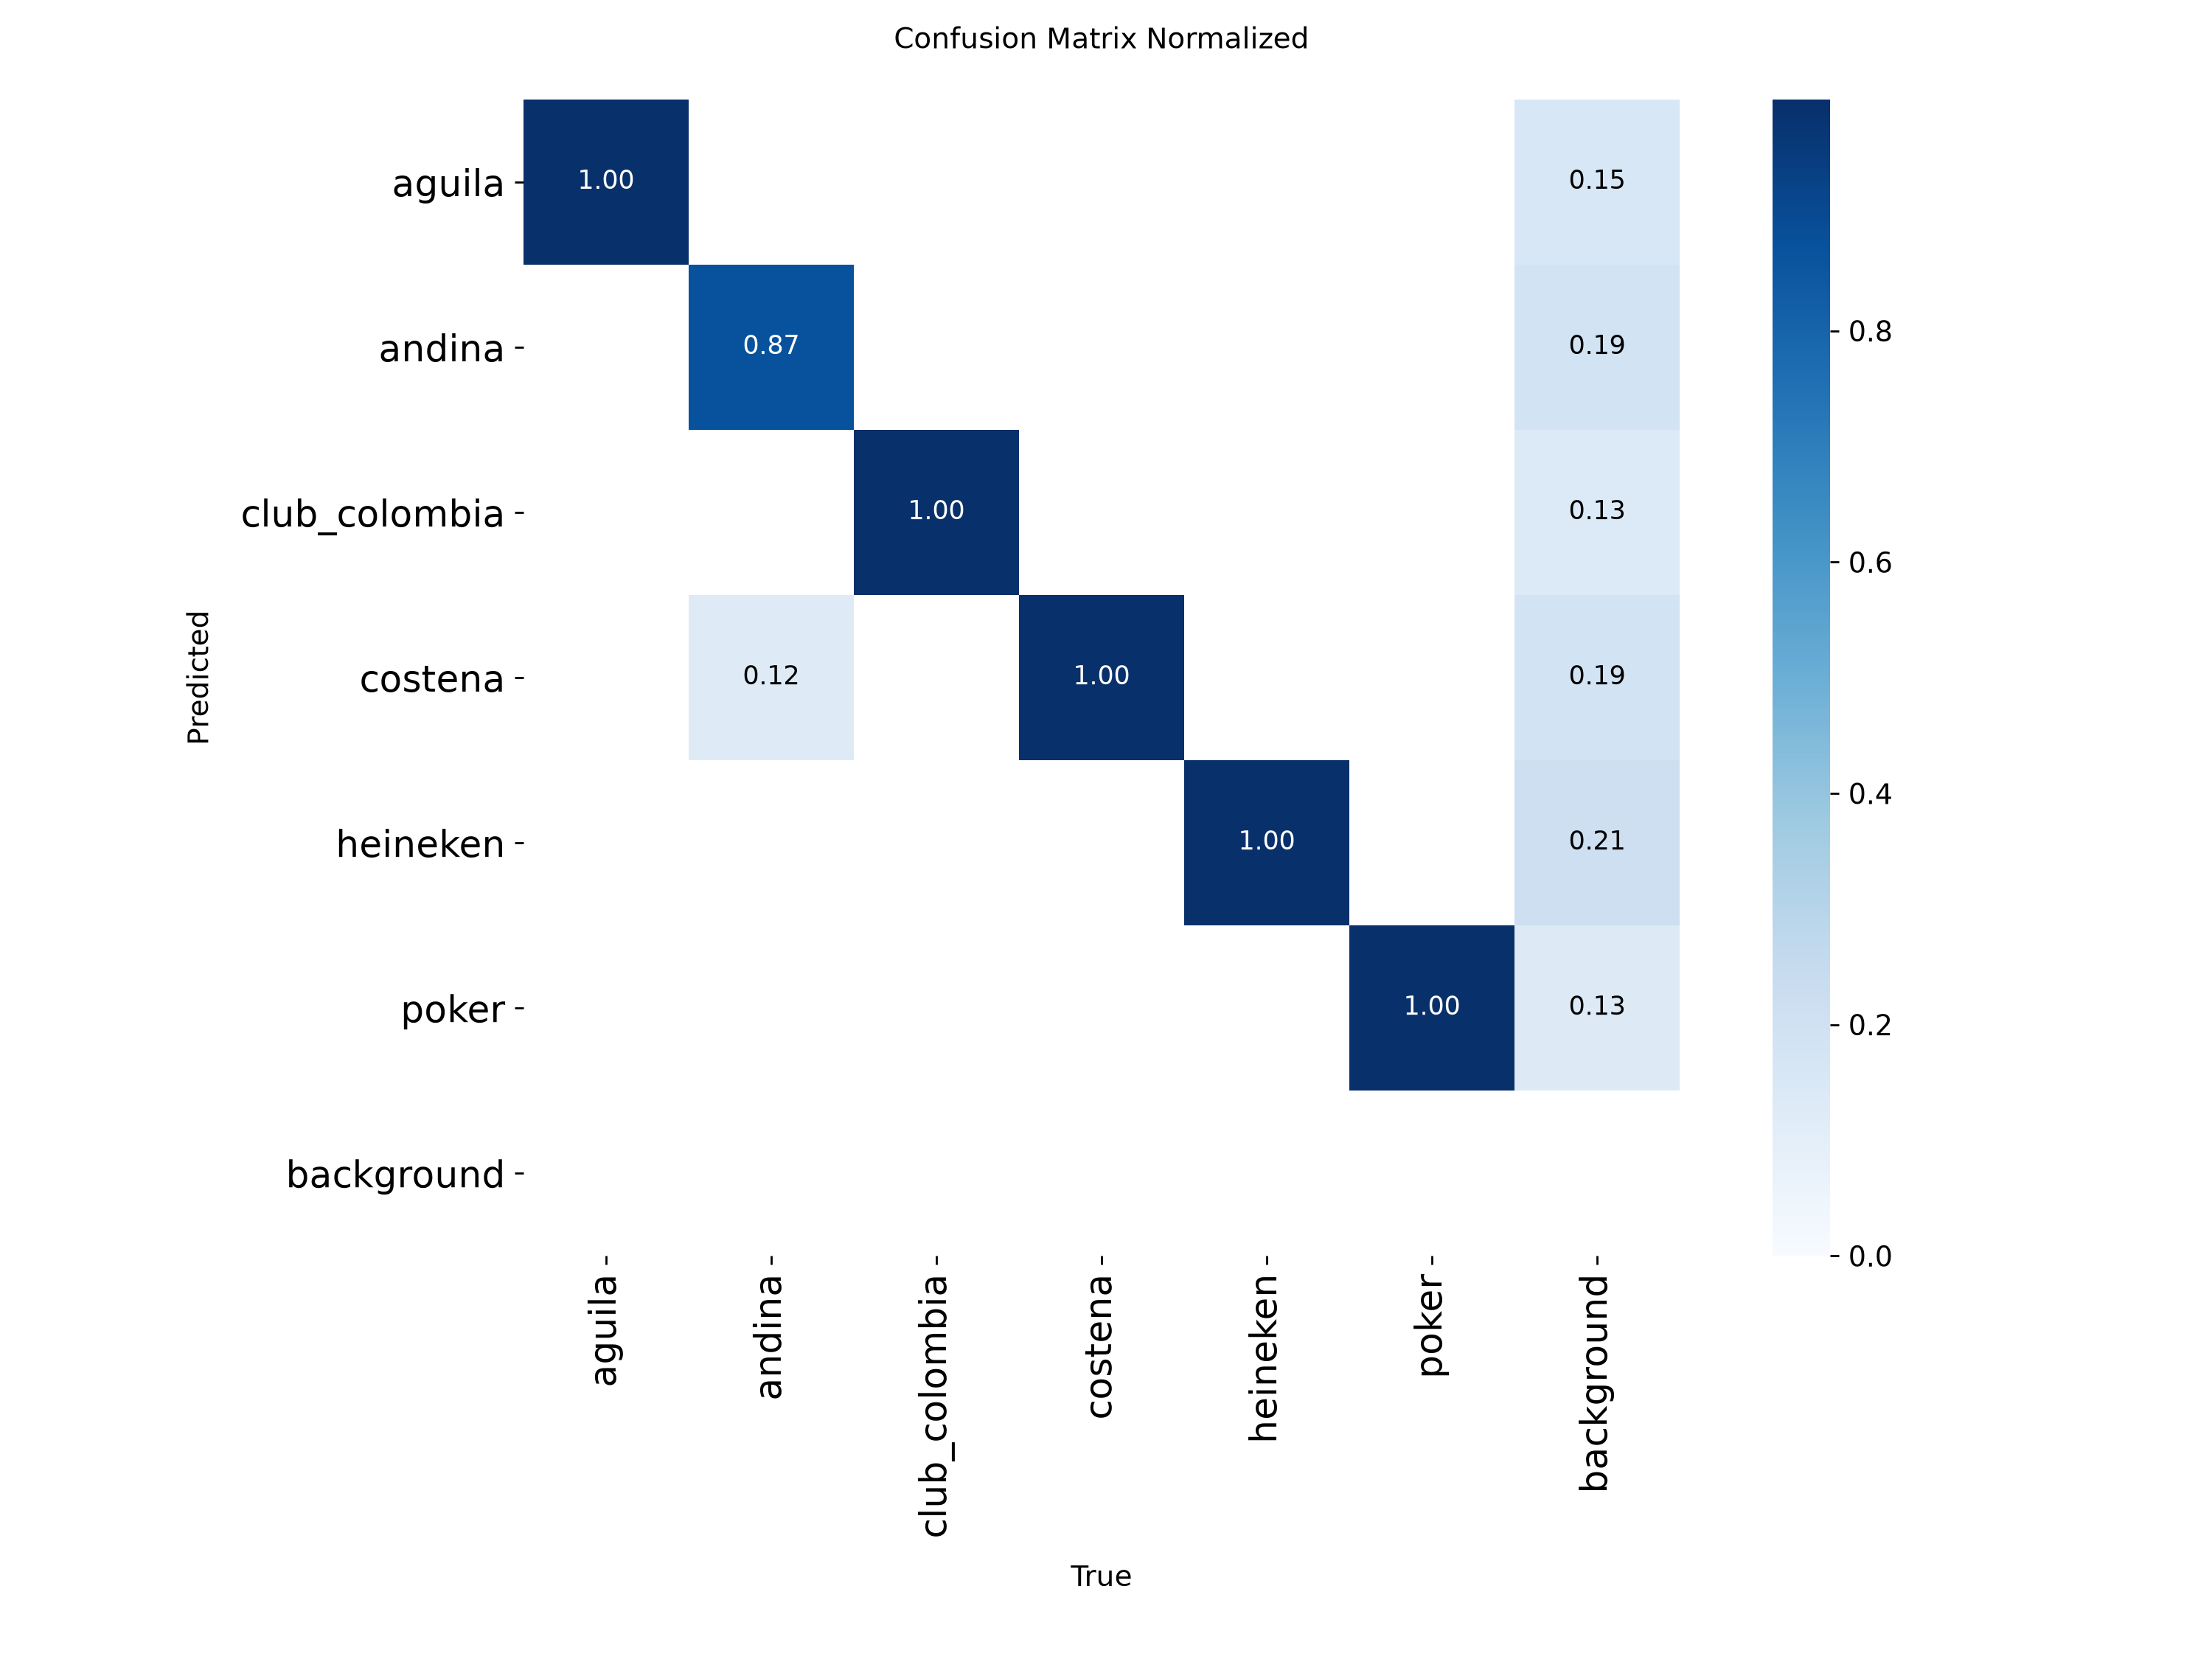

In [16]:
mostrar(RUN_NANO / "val" / "confusion_matrix.png", 800)
mostrar(RUN_NANO / "val" / "confusion_matrix_normalized.png", 800)

Ultralytics 8.4.196  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 370.9±84.2 MB/s, size: 37.9 KB)


val: Scanning C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\valid\labels.cache... 22 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 7.8s/it 2.4s<7.8s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3s/it 2.6s

... (6 outputs left out)

                 poker          7          7          1      0.857      0.855      0.824


Speed: 2.6ms preprocess, 12.5ms inference, 0.0ms loss, 0.9ms postprocess per image


Results saved to C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\nano_v4\val_conf40


confusion_matrix.png


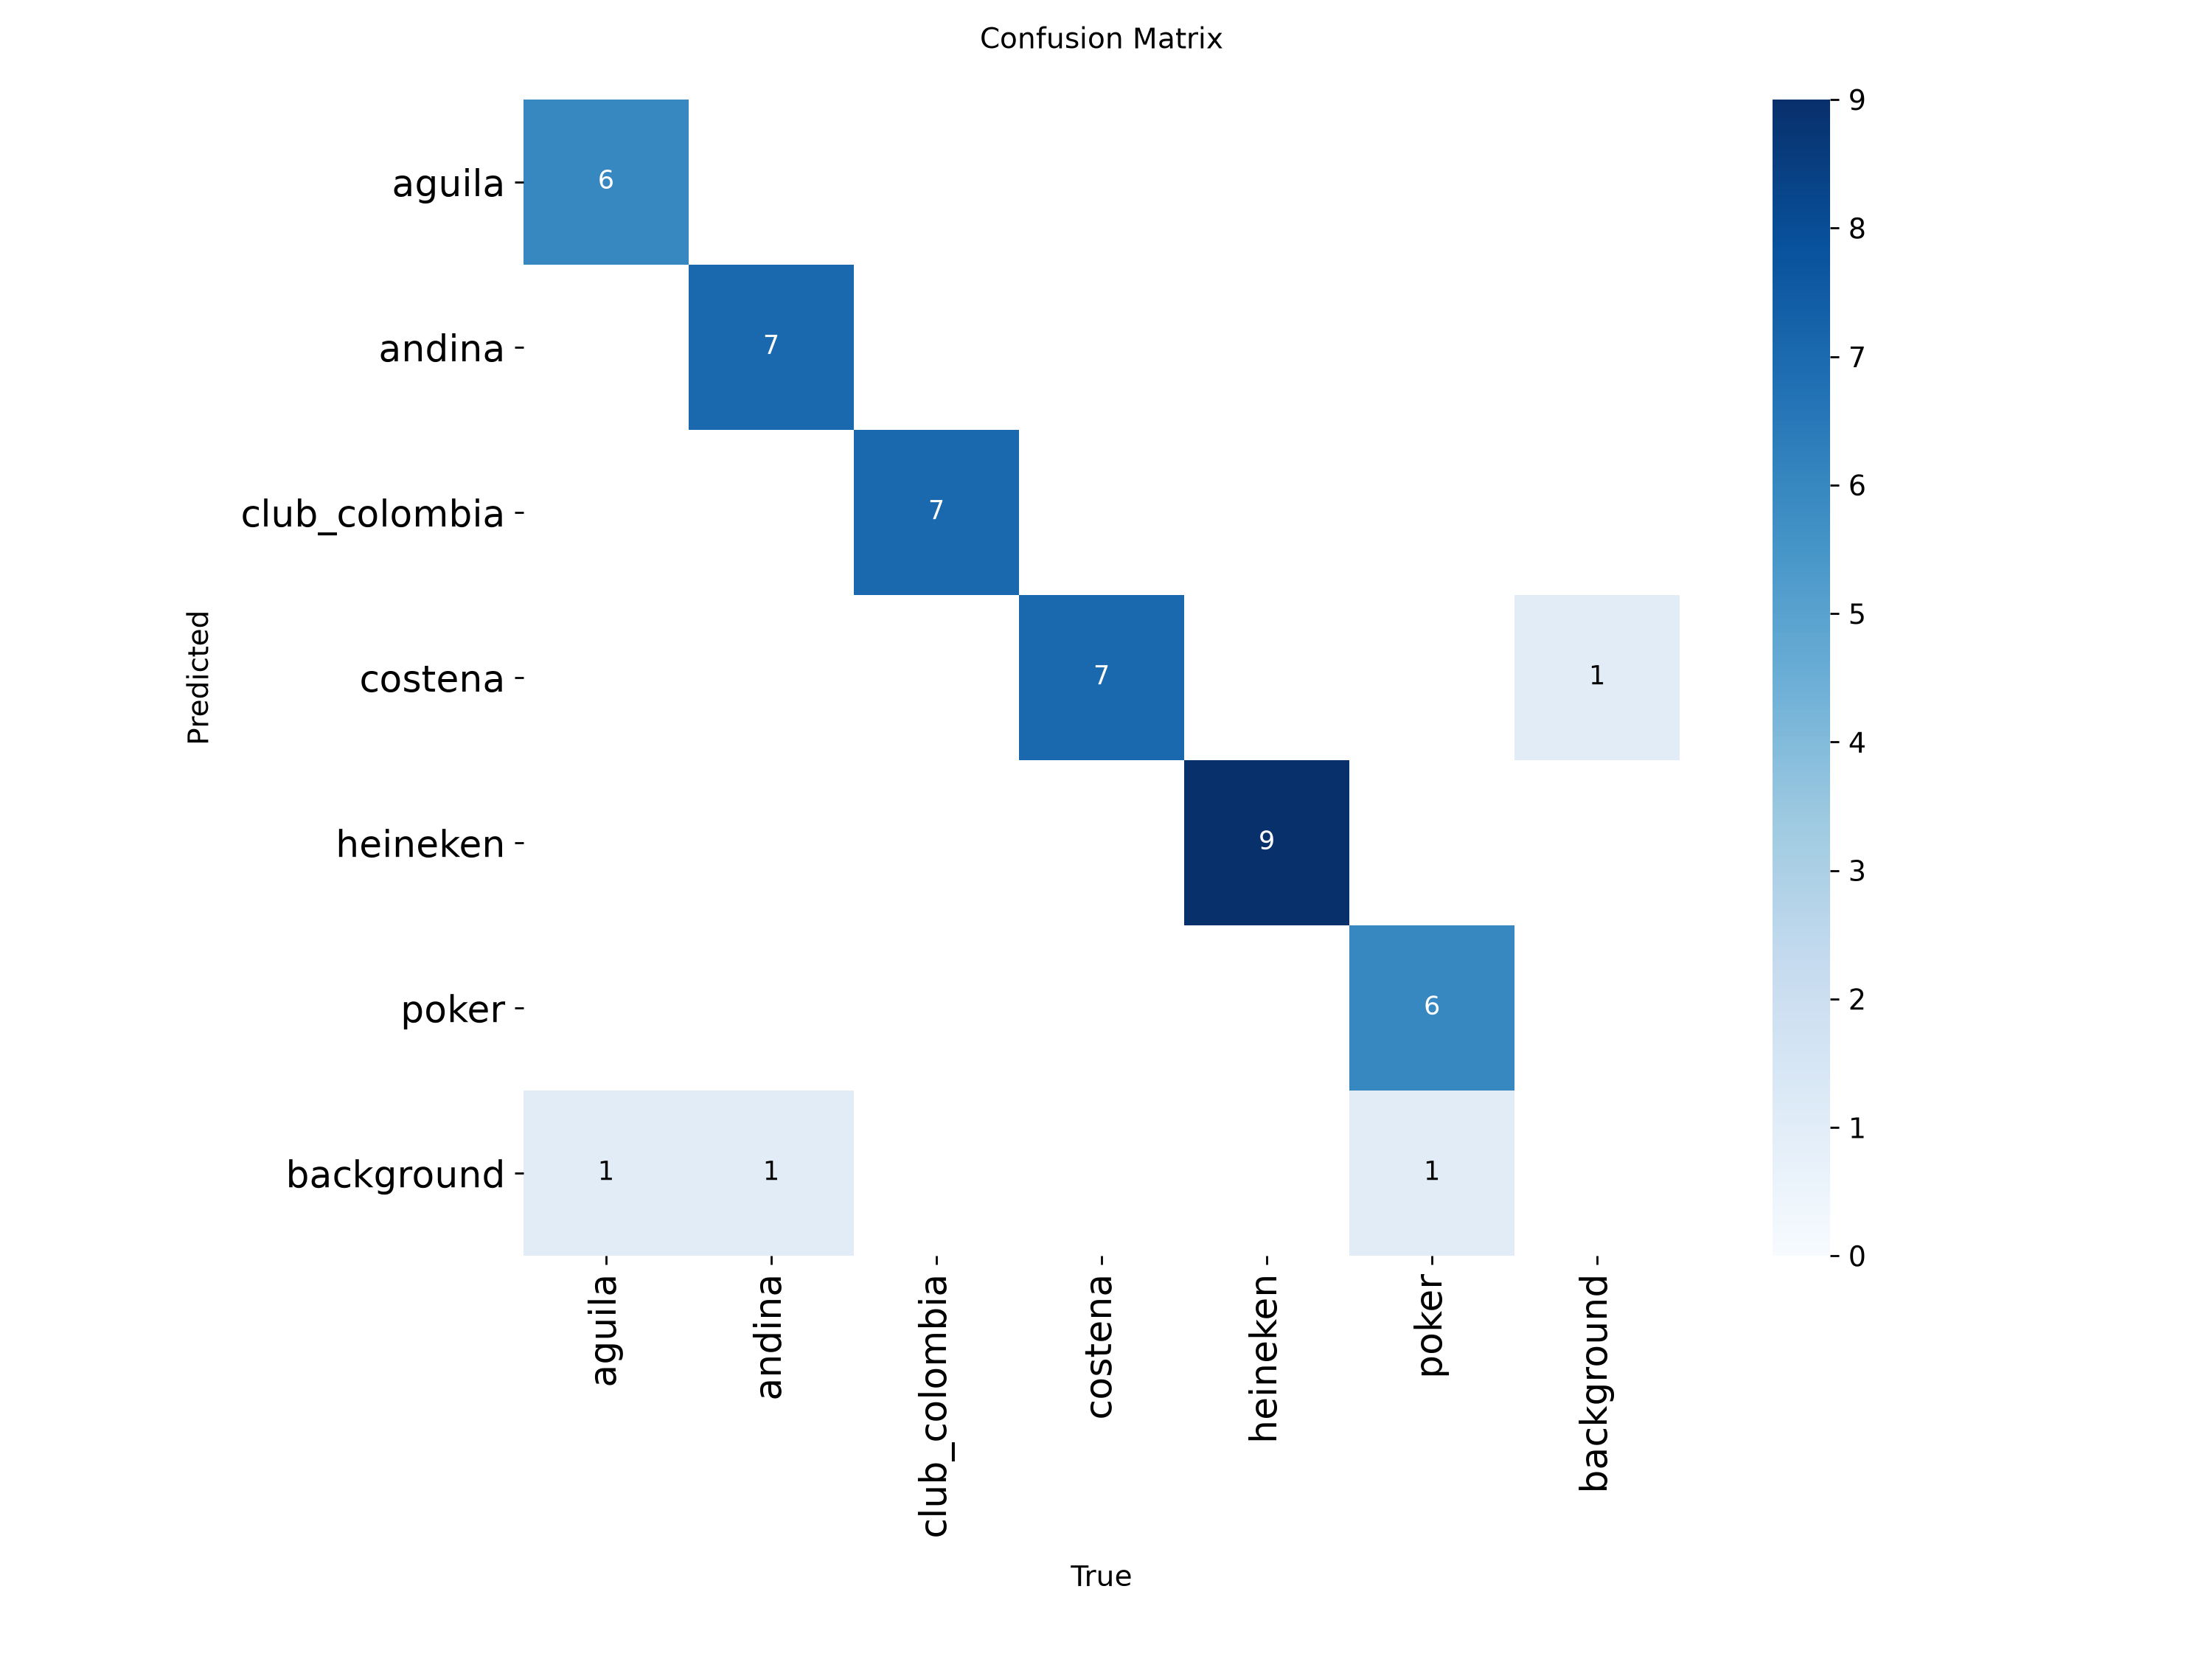

confusion_matrix_normalized.png


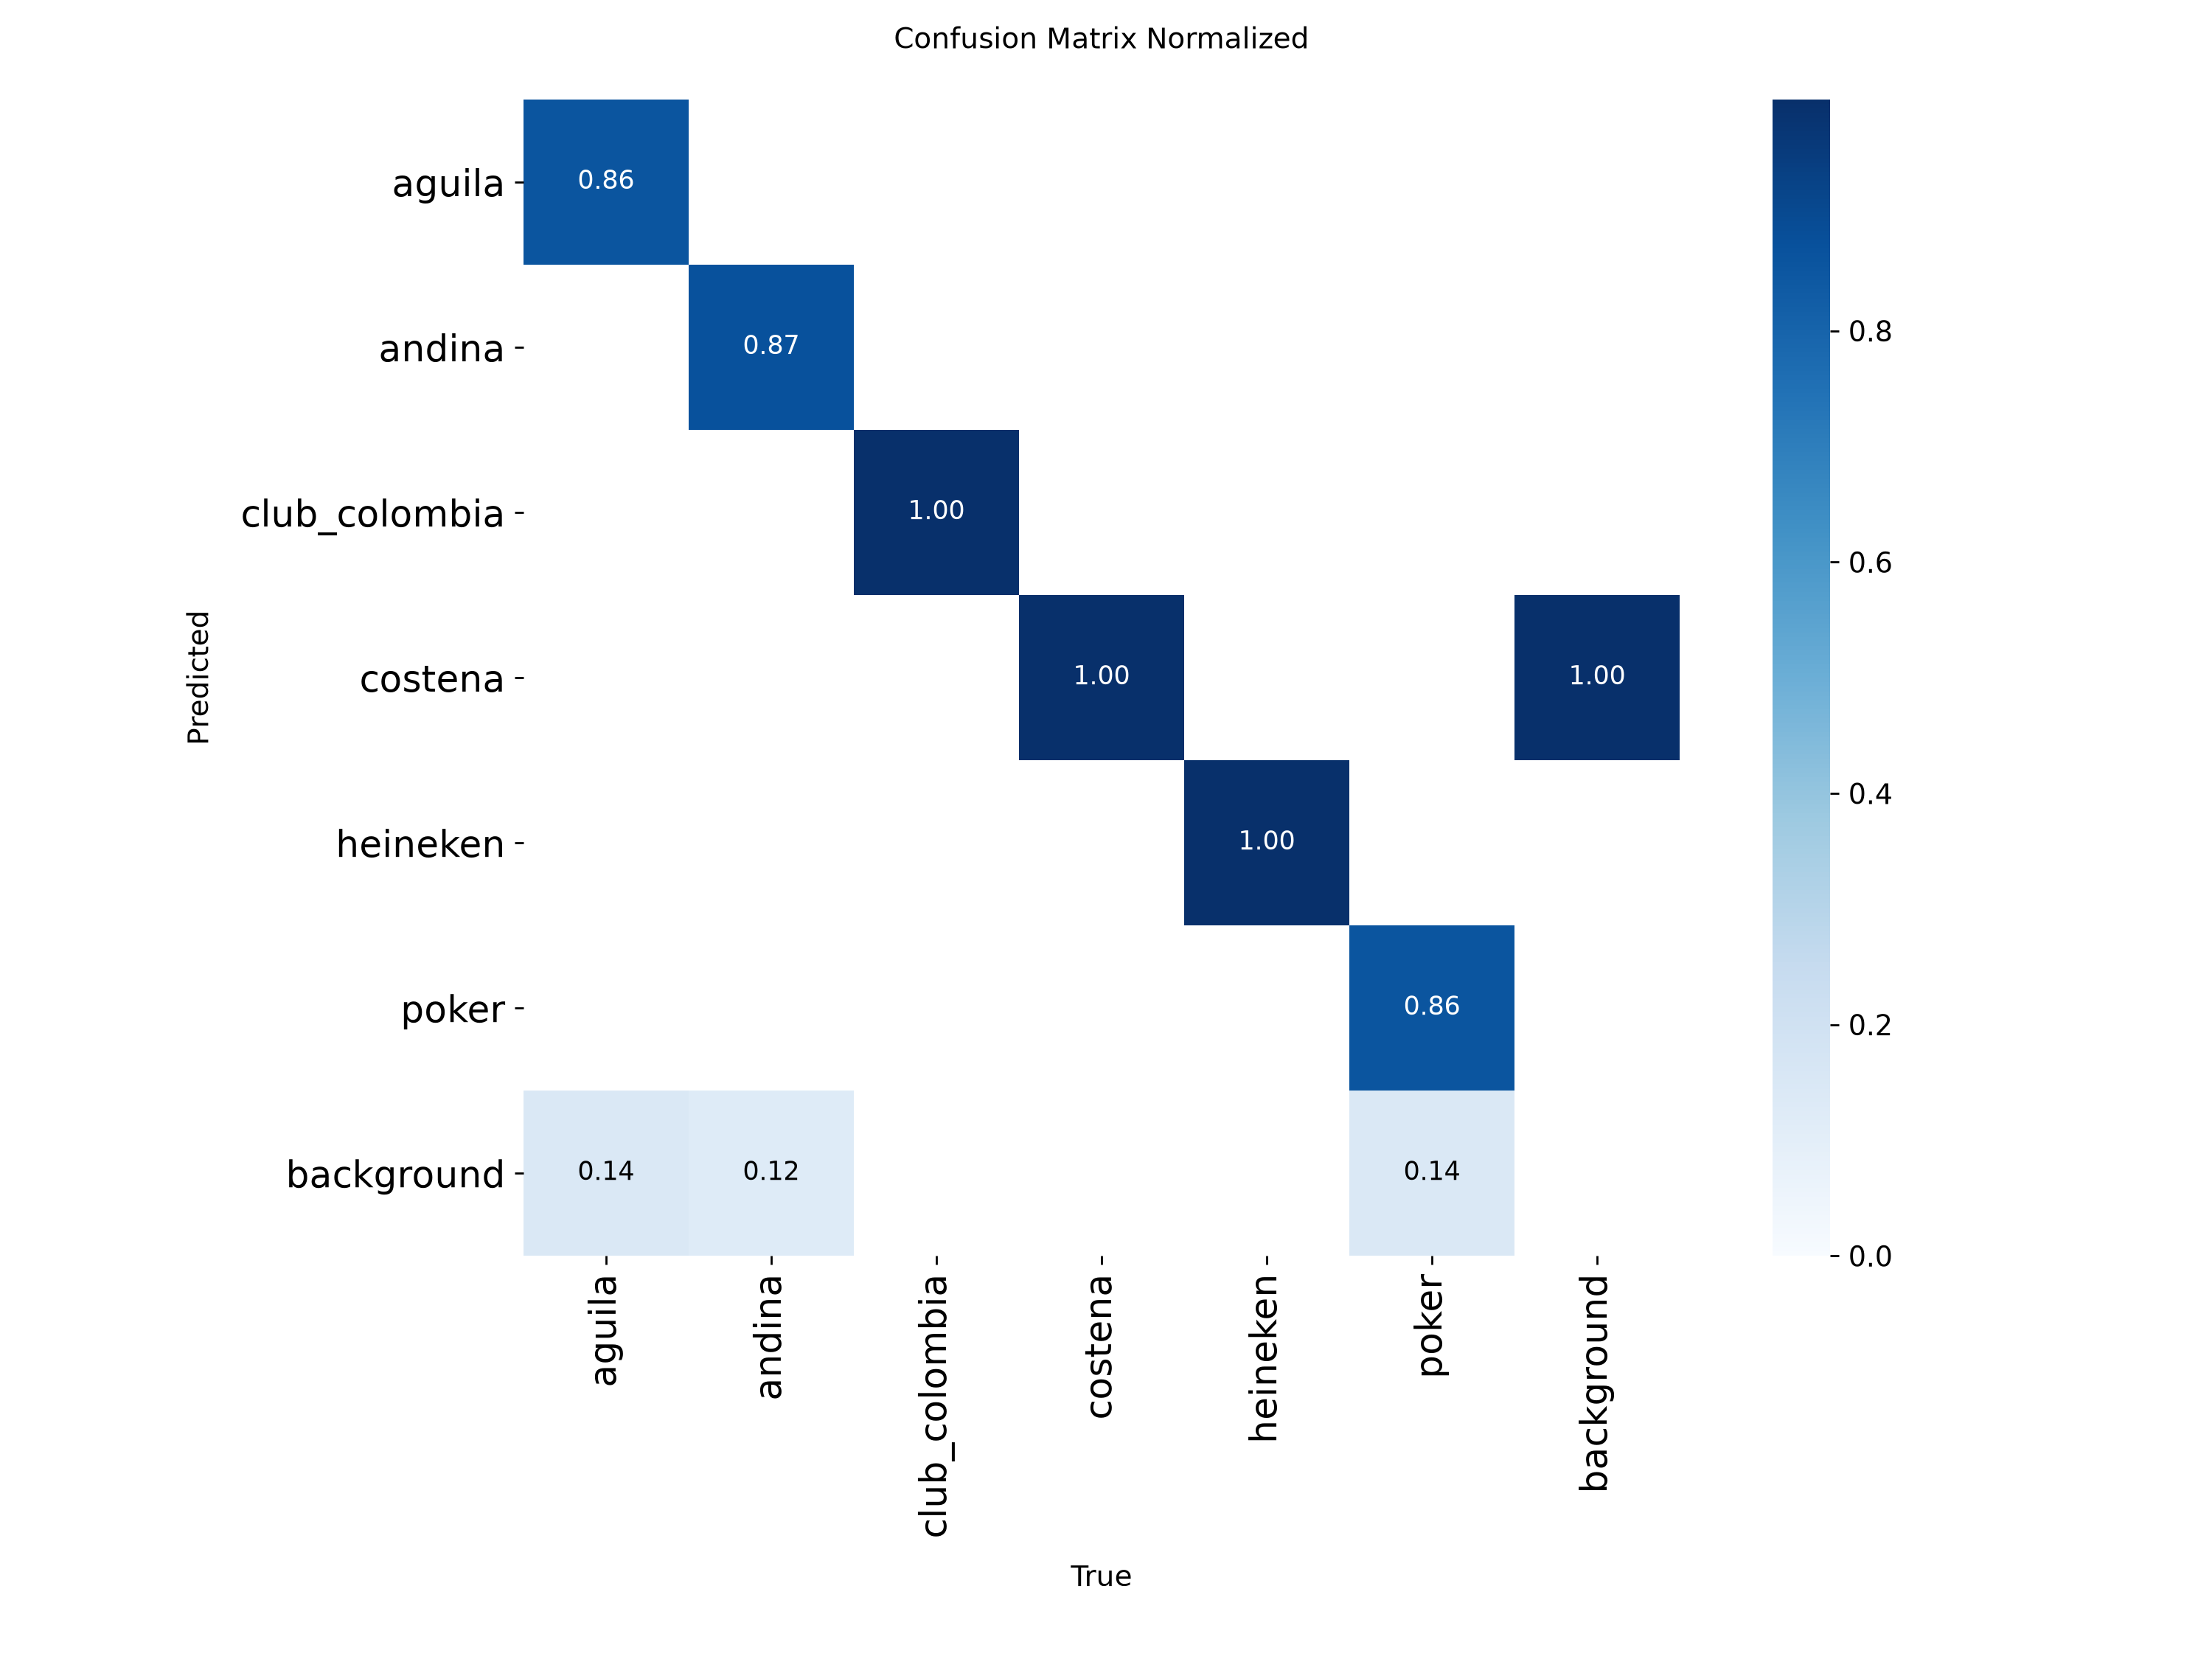

In [ ]:
CONF_MATRIZ = 0.40   # solo detecciones con confianza > 40 %
m_corte_nano = best_nano.val(data=str(DATA_YAML), split="val", conf=CONF_MATRIZ, plots=True, device=DEVICE,
                                project=str(RUN_NANO), name=f"val_conf{int(CONF_MATRIZ*100):02d}", exist_ok=True)
mostrar(RUN_NANO / f"val_conf{int(CONF_MATRIZ*100):02d}" / "confusion_matrix.png", 800)
mostrar(RUN_NANO / f"val_conf{int(CONF_MATRIZ*100):02d}" / "confusion_matrix_normalized.png", 800)

### Umbral de confianza
Cada detección trae una confianza. La curva F1 (`BoxF1_curve.png`) indica qué umbral da el mejor balance entre
precisión y recall. Ese valor es el que se usará en vivo: si las detecciones de baja confianza son malas, el umbral
las quita.

BoxF1_curve.png


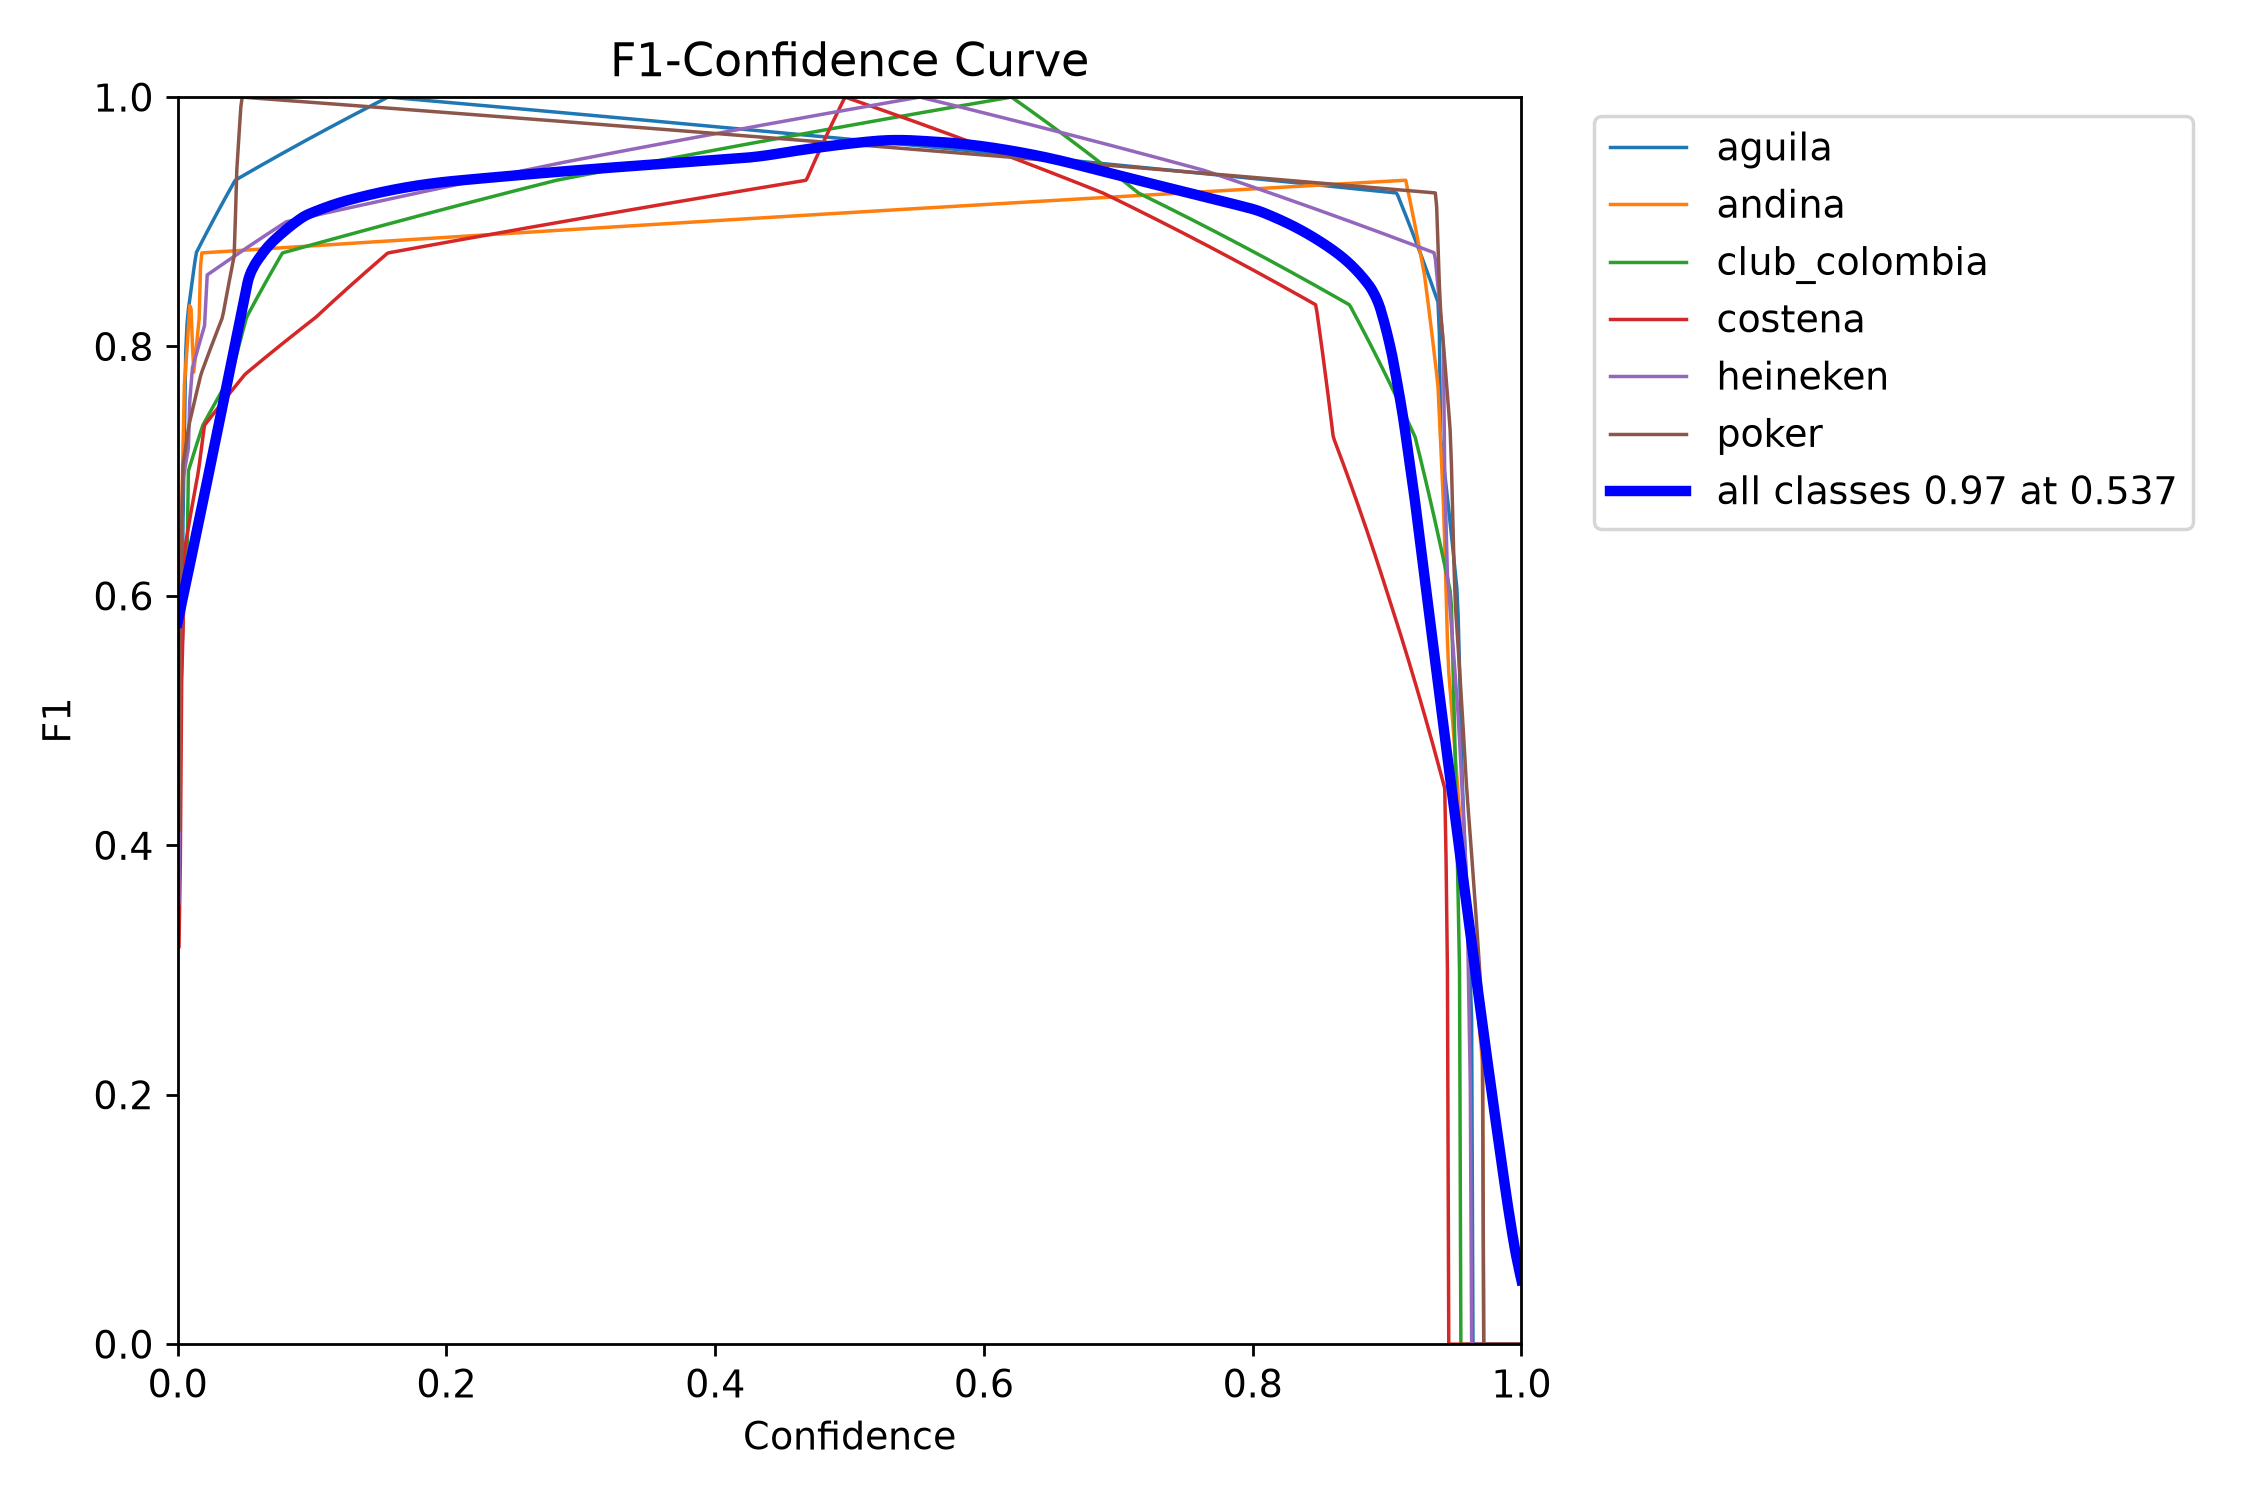

Umbral que maximiza F1 (nano): 0.50


In [17]:
def umbral_optimo(metrics):
    try:
        px, f1 = metrics.box.curves_results[1][0], metrics.box.curves_results[1][1]
        return float(px[f1.mean(0).argmax()])
    except Exception as e:
        print("No se pudo calcular (", e, "): revisar BoxF1_curve.png a mano")
        return 0.25

mostrar(RUN_NANO / "val" / "BoxF1_curve.png", 700)
CONF_NANO = umbral_optimo(metrics_nano)
print(f"Umbral que maximiza F1 (nano): {CONF_NANO:.2f}")

### Inferencia en las imágenes de *test* (nunca vistas en el entrenamiento)
En clase se usaba el `detect.py` de YOLOv5. Con `ultralytics` es `model.val(split="test")` para las métricas y
`model.predict(..., save=True)` para ver las imágenes.

Ultralytics 8.4.196  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 383.5±85.4 MB/s, size: 30.6 KB)


val: Scanning C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\test\labels... 11 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 11/11  0.0s

val: New cache created: C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\test\labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 6.3it/s 0.2s

... (7 outputs left out)

Speed: 0.4ms preprocess, 7.1ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\nano_v4\test


Results saved to C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\nano_v4\pred_test


4_jpeg.rf.402c2a88f1a06390417250829975390b.jpg


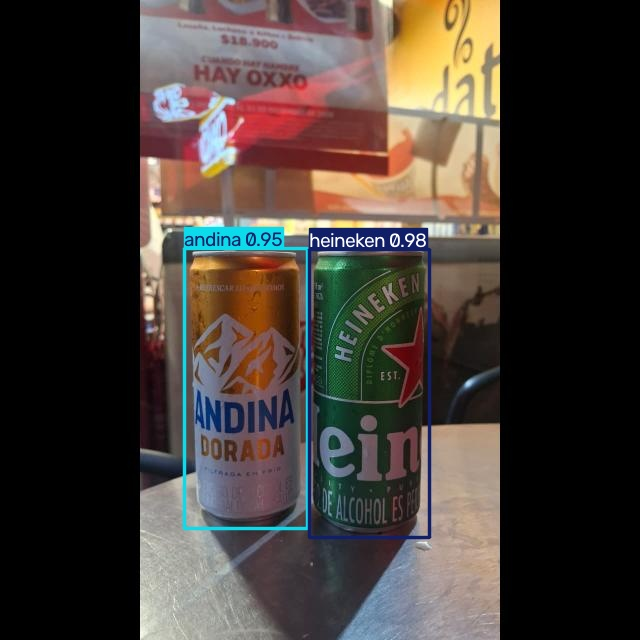

Foto8PR_jpeg.rf.115ac1a3fb77b0bf952b31c77e0c5e8c.jpg


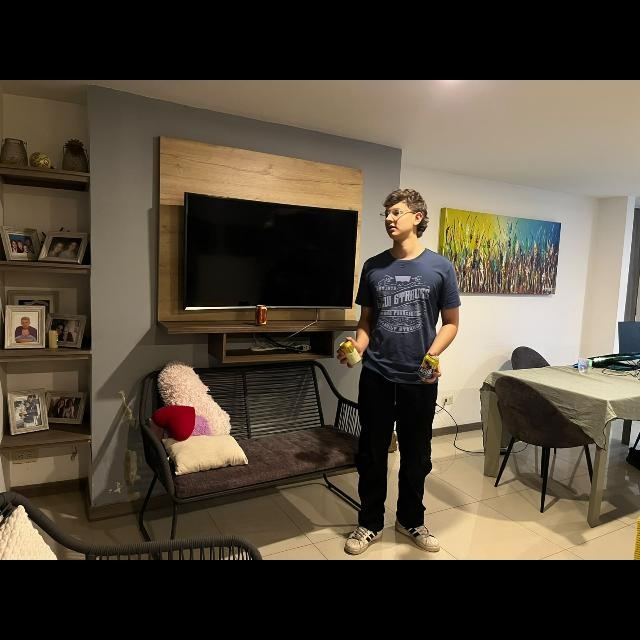

IMG_1725_jpeg.rf.3e582040a51fd14b4592c5b50af2e65c.jpg


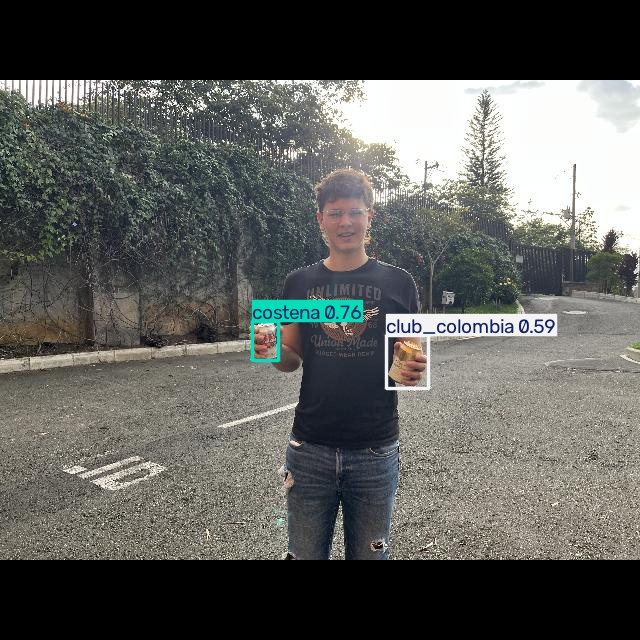

IMG_1750_jpeg.rf.080a8eca39c0ef776d06d4383e8f7652.jpg


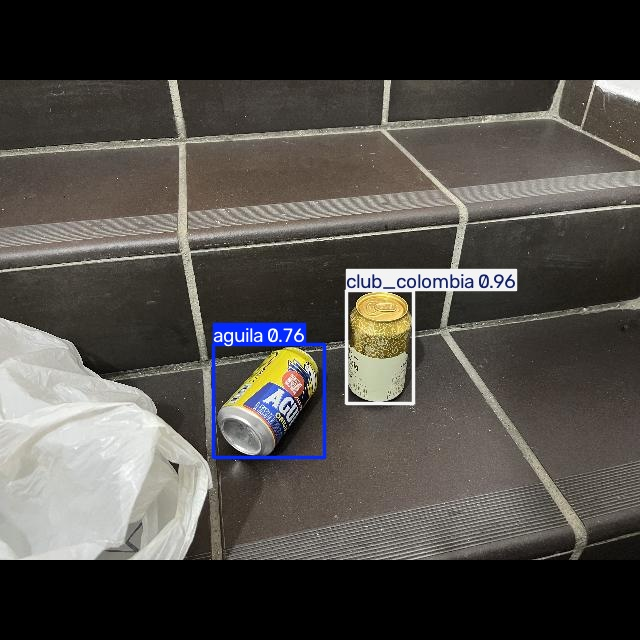

IMG_9914_EQF_jpeg.rf.44e7682a56d8650e54c5694ae374ab31.jpg


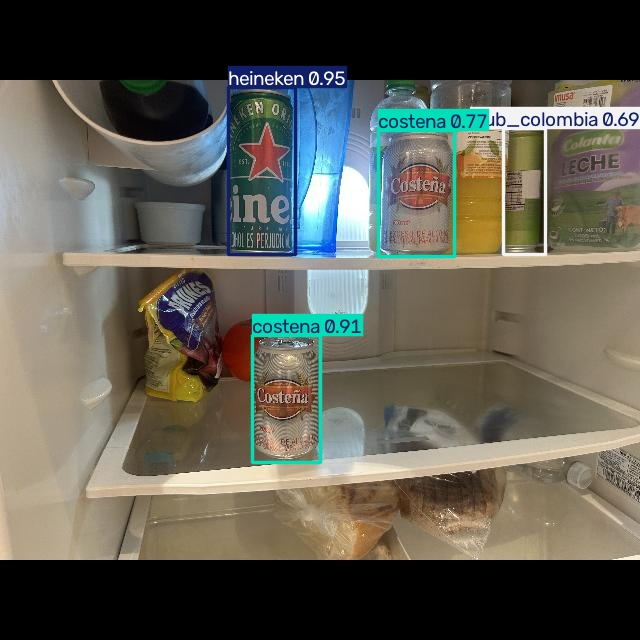

WhatsApp-Image-2026-10-27-at-10-52-18-PM-2-_jpeg.rf.3c37db9fad41b27c04c51615d057b8cd.jpg


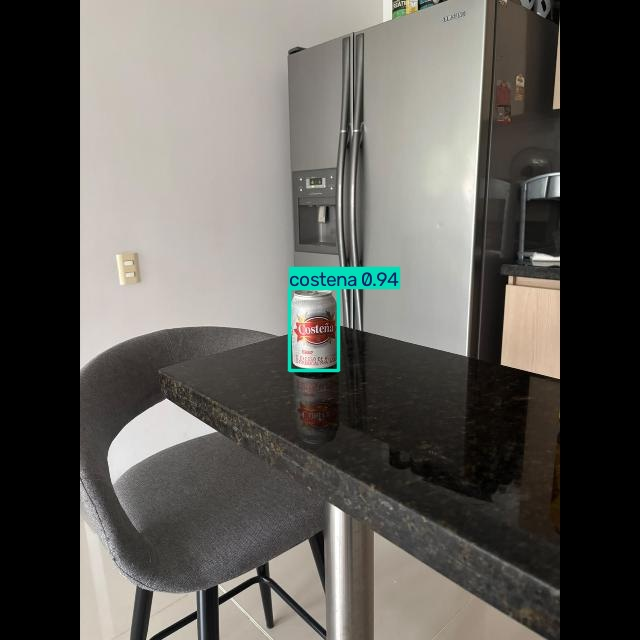

=== NANO - test ===
P 0.839 | R 0.840 | mAP50 0.874 | mAP50-95 0.750 | mAP75 0.819
  aguila          P 0.70  R 0.50  mAP50 0.64  mAP50-95 0.52
  andina          P 0.79  R 1.00  mAP50 0.99  mAP50-95 0.99
  club_colombia   P 0.80  R 0.80  mAP50 0.90  mAP50-95 0.75
  costena         P 0.86  R 1.00  mAP50 0.97  mAP50-95 0.86
  heineken        P 0.89  R 1.00  mAP50 0.99  mAP50-95 0.80
  poker           P 1.00  R 0.74  mAP50 0.74  mAP50-95 0.57


In [18]:
def probar_en_test(best, run_dir, conf):
    if not TIENE_TEST:
        print("El dataset no tiene carpeta test")
        return None
    m = best.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, device=DEVICE, plots=True,
                 project=str(run_dir), name="test", exist_ok=True)
    best.predict(str(DATASET_DIR / "test" / "images"), conf=conf, imgsz=IMGSZ, device=DEVICE,
                 save=True, project=str(run_dir), name="pred_test", exist_ok=True, verbose=False)
    for p in sorted((run_dir / "pred_test").glob("*.jpg"))[:6]:
        mostrar(p, 600)
    return m

test_nano = probar_en_test(best_nano, RUN_NANO, CONF_NANO)
if test_nano:
    resumen(test_nano, "NANO - test")

## 6. Modelo 2 — YOLO26 **small** (un poco más grande y preciso)
Exactamente los mismos pasos con `yolo26s.pt`. Más adelante se puede subir a `m` o `l` (el "modelo potente")
cambiando solo el nombre del modelo.

Ultralytics 8.4.196  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=small_v4, nbs=64, nms=

Overriding model.yaml nc=80 with nc=6



                   from  n    params  module                                       arguments                     


  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 


  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                


... (2,235 outputs left out)

                 poker          7          7          1      0.886      0.995      0.926


Speed: 0.9ms preprocess, 11.5ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\small_v4


results.png


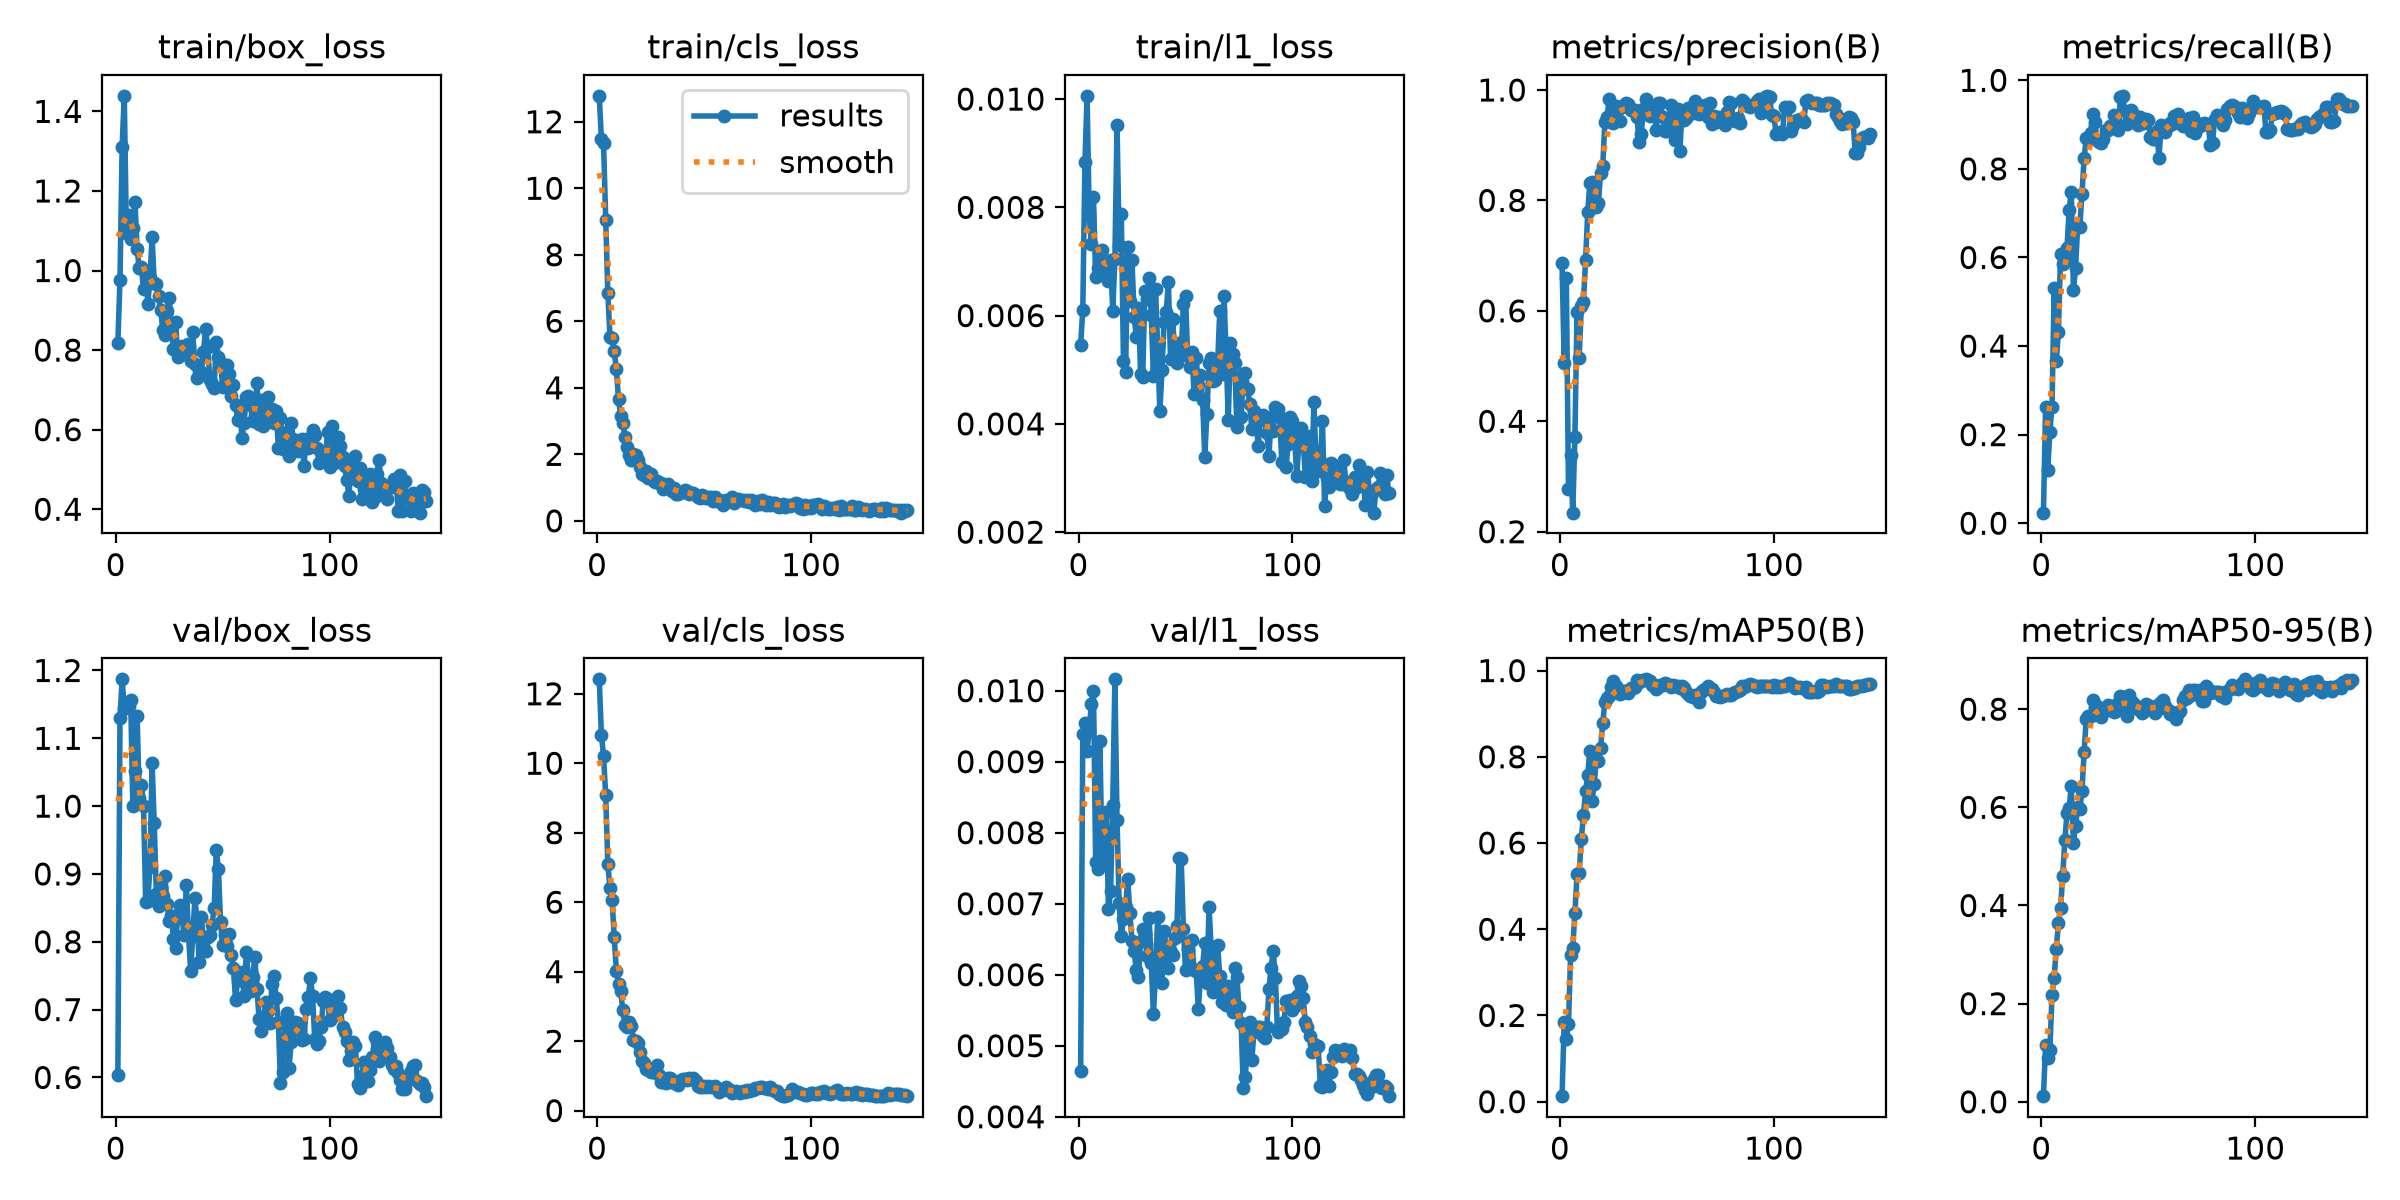

In [19]:
model_small = YOLO("yolo26s.pt")
results_small = model_small.train(data=str(DATA_YAML), epochs=EPOCAS, imgsz=IMGSZ,
                                  project=str(path), name=subpath_small,
                                  val=True, patience=PACIENCIA, batch=BATCH, workers=WORKERS,
                                  device=DEVICE, fliplr=0.0, seed=0)
RUN_SMALL = Path(model_small.trainer.save_dir)
mostrar(RUN_SMALL / "results.png", 1000)

Ultralytics 8.4.196  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 527.0±162.8 MB/s, size: 44.4 KB)


val: Scanning C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\valid\labels.cache... 22 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 8.3s/it 2.5s<8.3s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3s/it 2.6s

... (6 outputs left out)

                 poker          7          7          1      0.886      0.995      0.926


Speed: 2.8ms preprocess, 21.9ms inference, 0.0ms loss, 0.9ms postprocess per image


Results saved to C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\small_v4\val


=== SMALL - validación ===
P 0.984 | R 0.917 | mAP50 0.964 | mAP50-95 0.854 | mAP75 0.964
  aguila          P 0.93  R 1.00  mAP50 0.99  mAP50-95 0.88
  andina          P 1.00  R 0.88  mAP50 0.88  mAP50-95 0.74
  club_colombia   P 0.99  R 1.00  mAP50 0.99  mAP50-95 0.82
  costena         P 1.00  R 0.74  mAP50 0.93  mAP50-95 0.88
  heineken        P 0.99  R 1.00  mAP50 0.99  mAP50-95 0.87
  poker           P 1.00  R 0.89  mAP50 0.99  mAP50-95 0.93
confusion_matrix.png


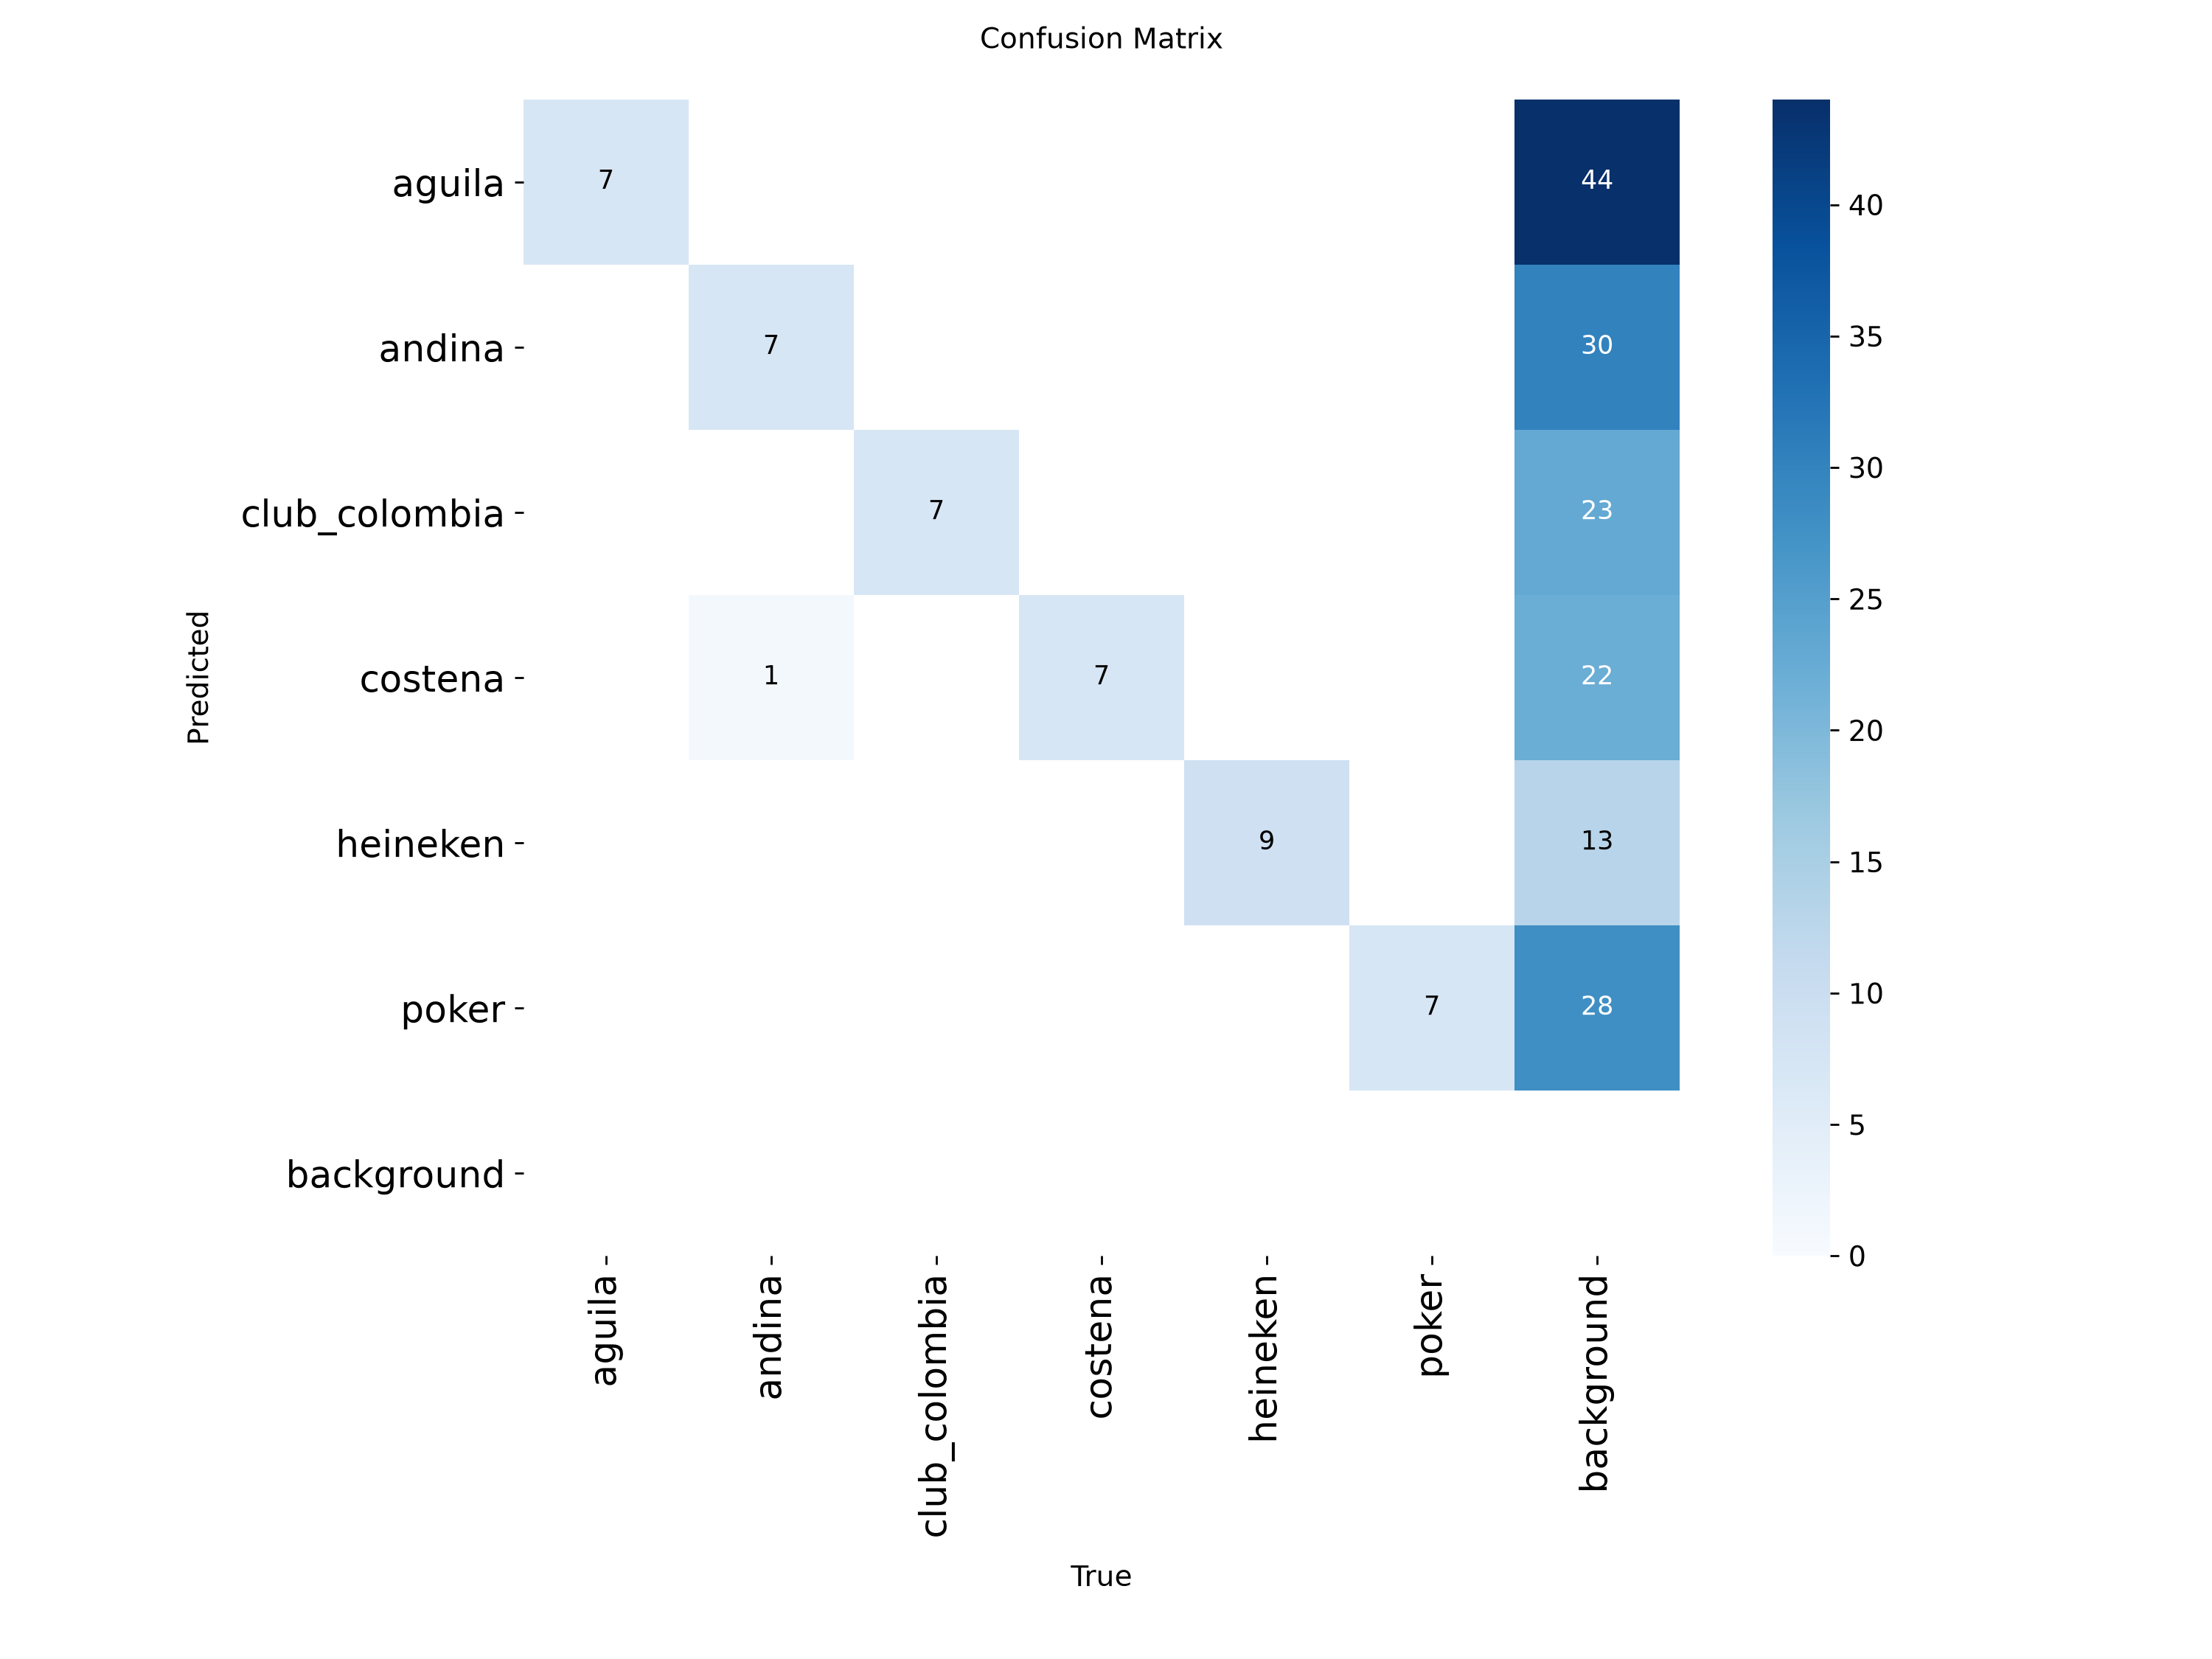

Umbral que maximiza F1 (small): 0.76


In [20]:
best_small = YOLO(RUN_SMALL / "weights" / "best.pt")
metrics_small = best_small.val(data=str(DATA_YAML), split="val", imgsz=IMGSZ, device=DEVICE, plots=True,
                               project=str(RUN_SMALL), name="val", exist_ok=True)
resumen(metrics_small, "SMALL - validación")
mostrar(RUN_SMALL / "val" / "confusion_matrix.png", 800)
CONF_SMALL = umbral_optimo(metrics_small)
print(f"Umbral que maximiza F1 (small): {CONF_SMALL:.2f}")

Ultralytics 8.4.196  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 294.2±147.0 MB/s, size: 34.9 KB)


val: Scanning C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\valid\labels.cache... 22 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 8.3s/it 2.5s<8.3s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3s/it 2.7s

... (6 outputs left out)

                 poker          7          7          1      0.857      0.855        0.8


Speed: 3.2ms preprocess, 22.4ms inference, 0.0ms loss, 1.0ms postprocess per image


Results saved to C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\small_v4\val_conf40


confusion_matrix.png


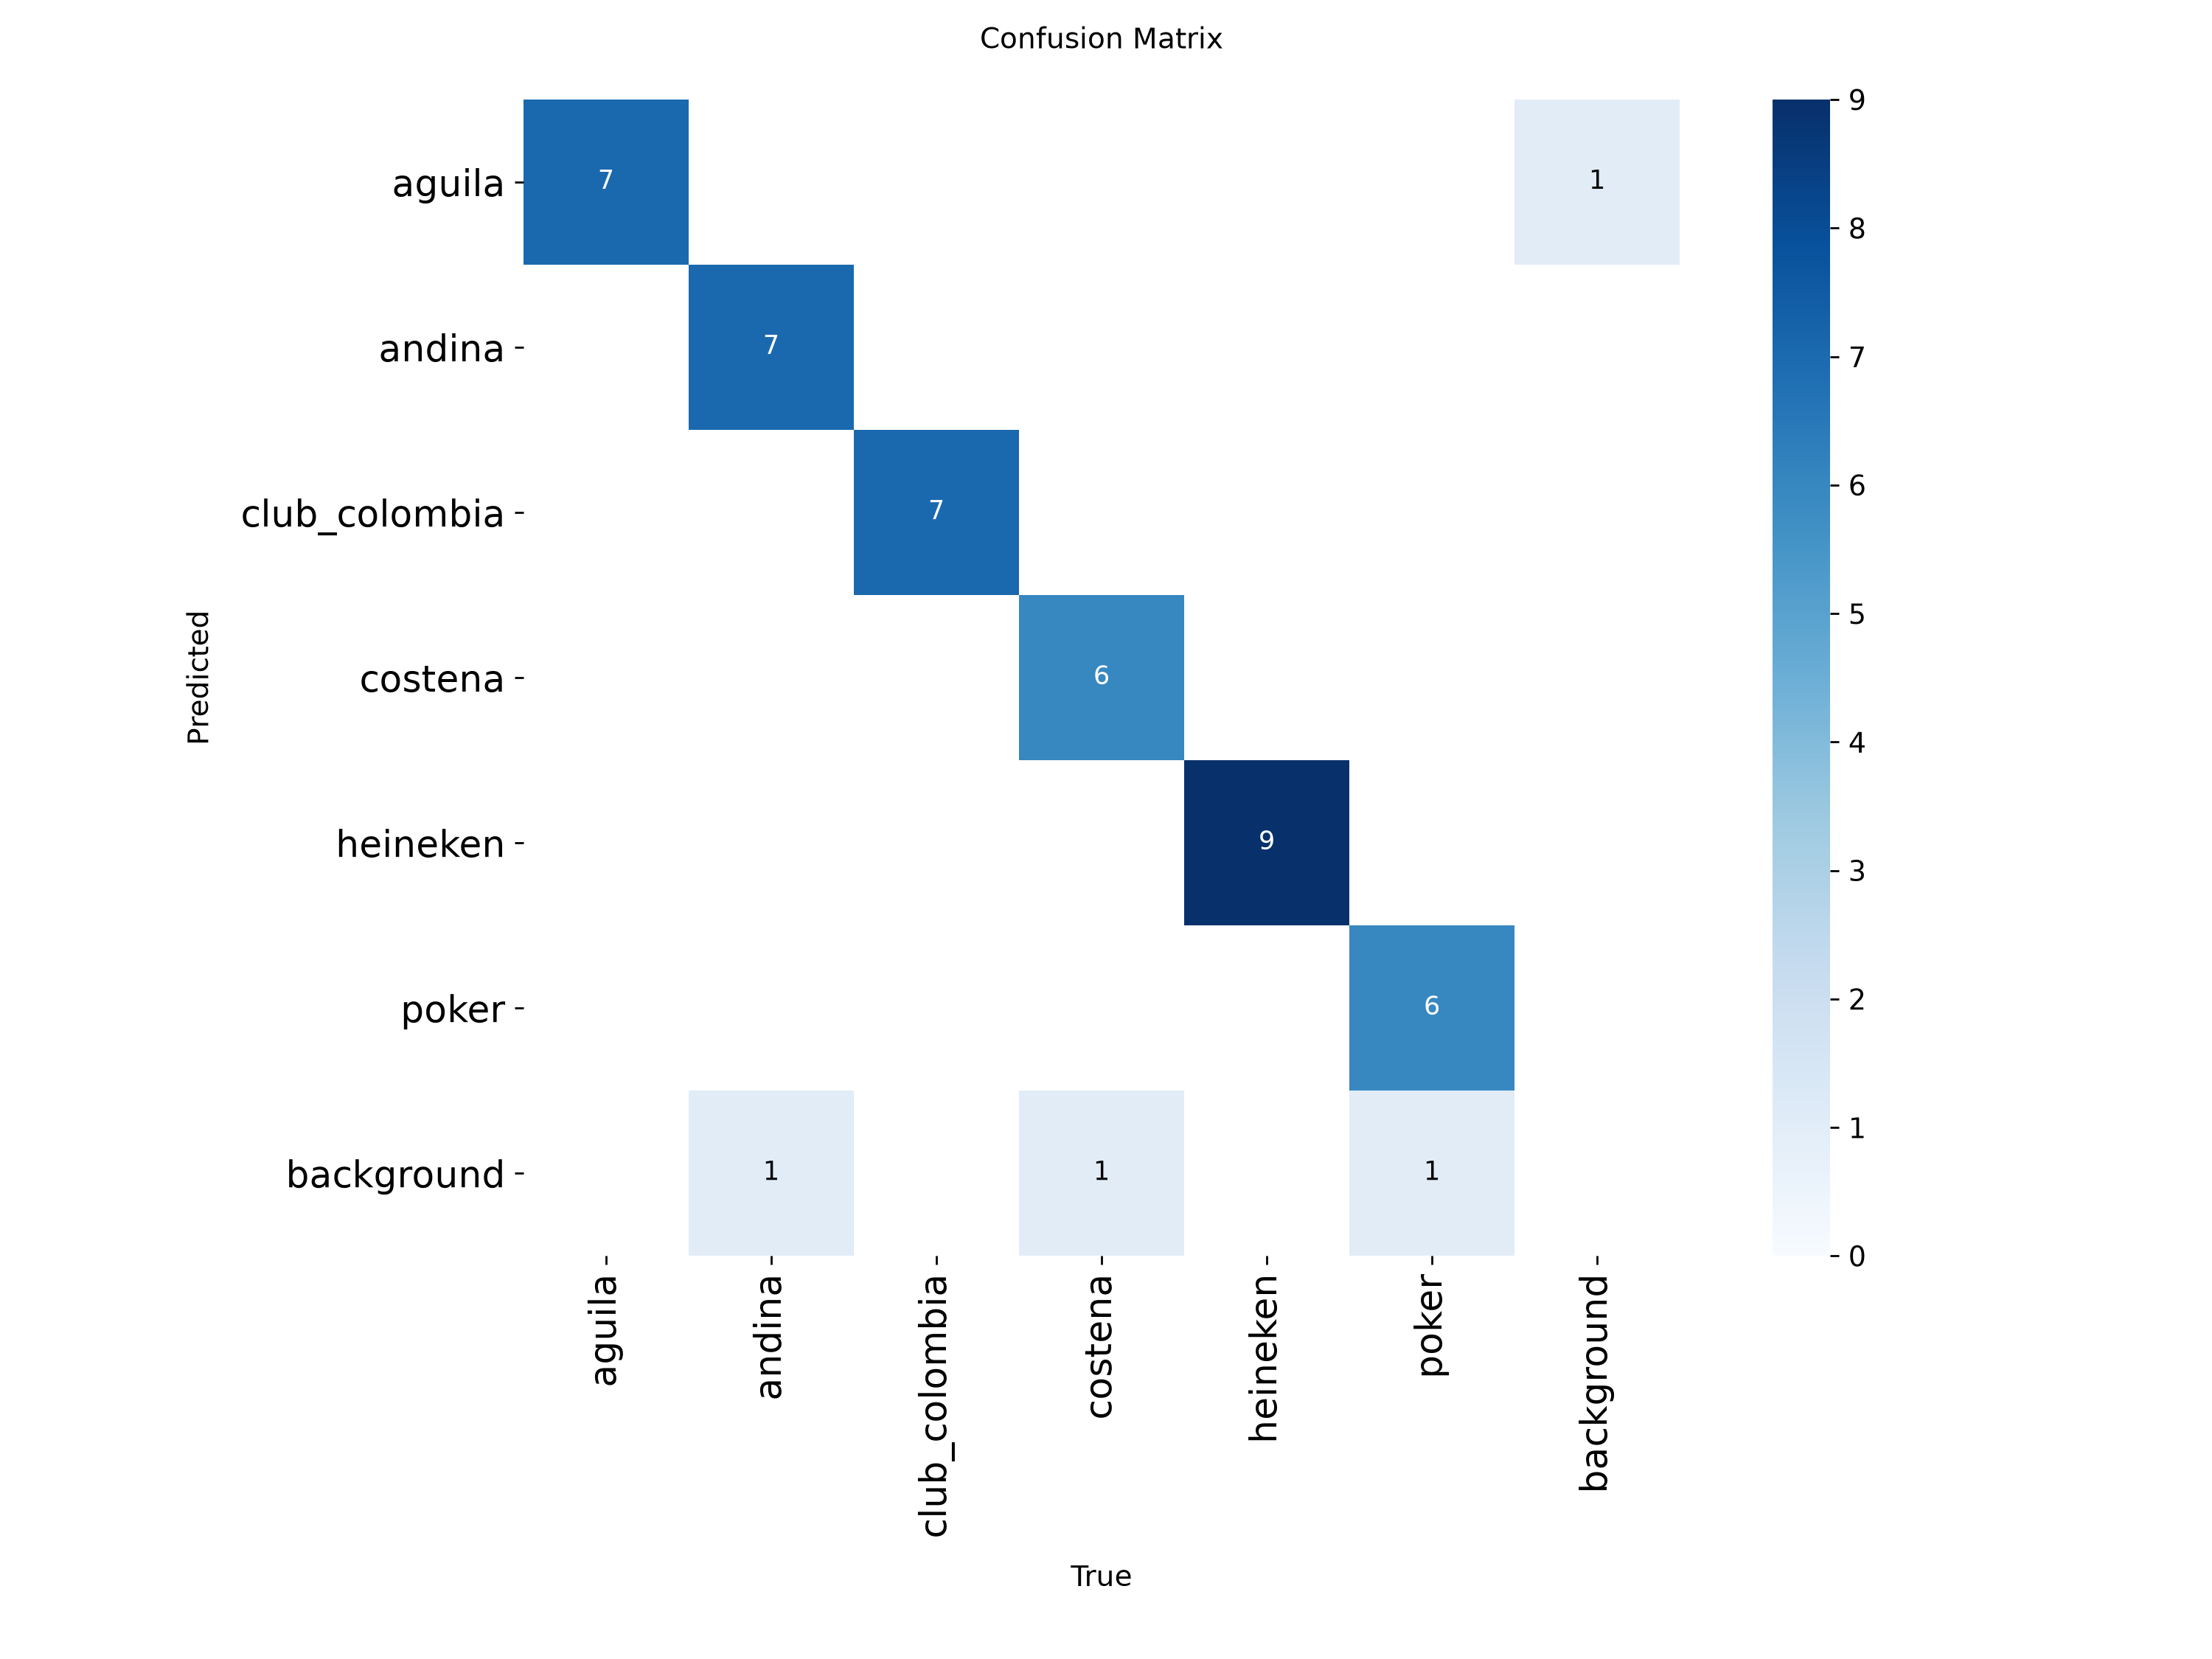

confusion_matrix_normalized.png


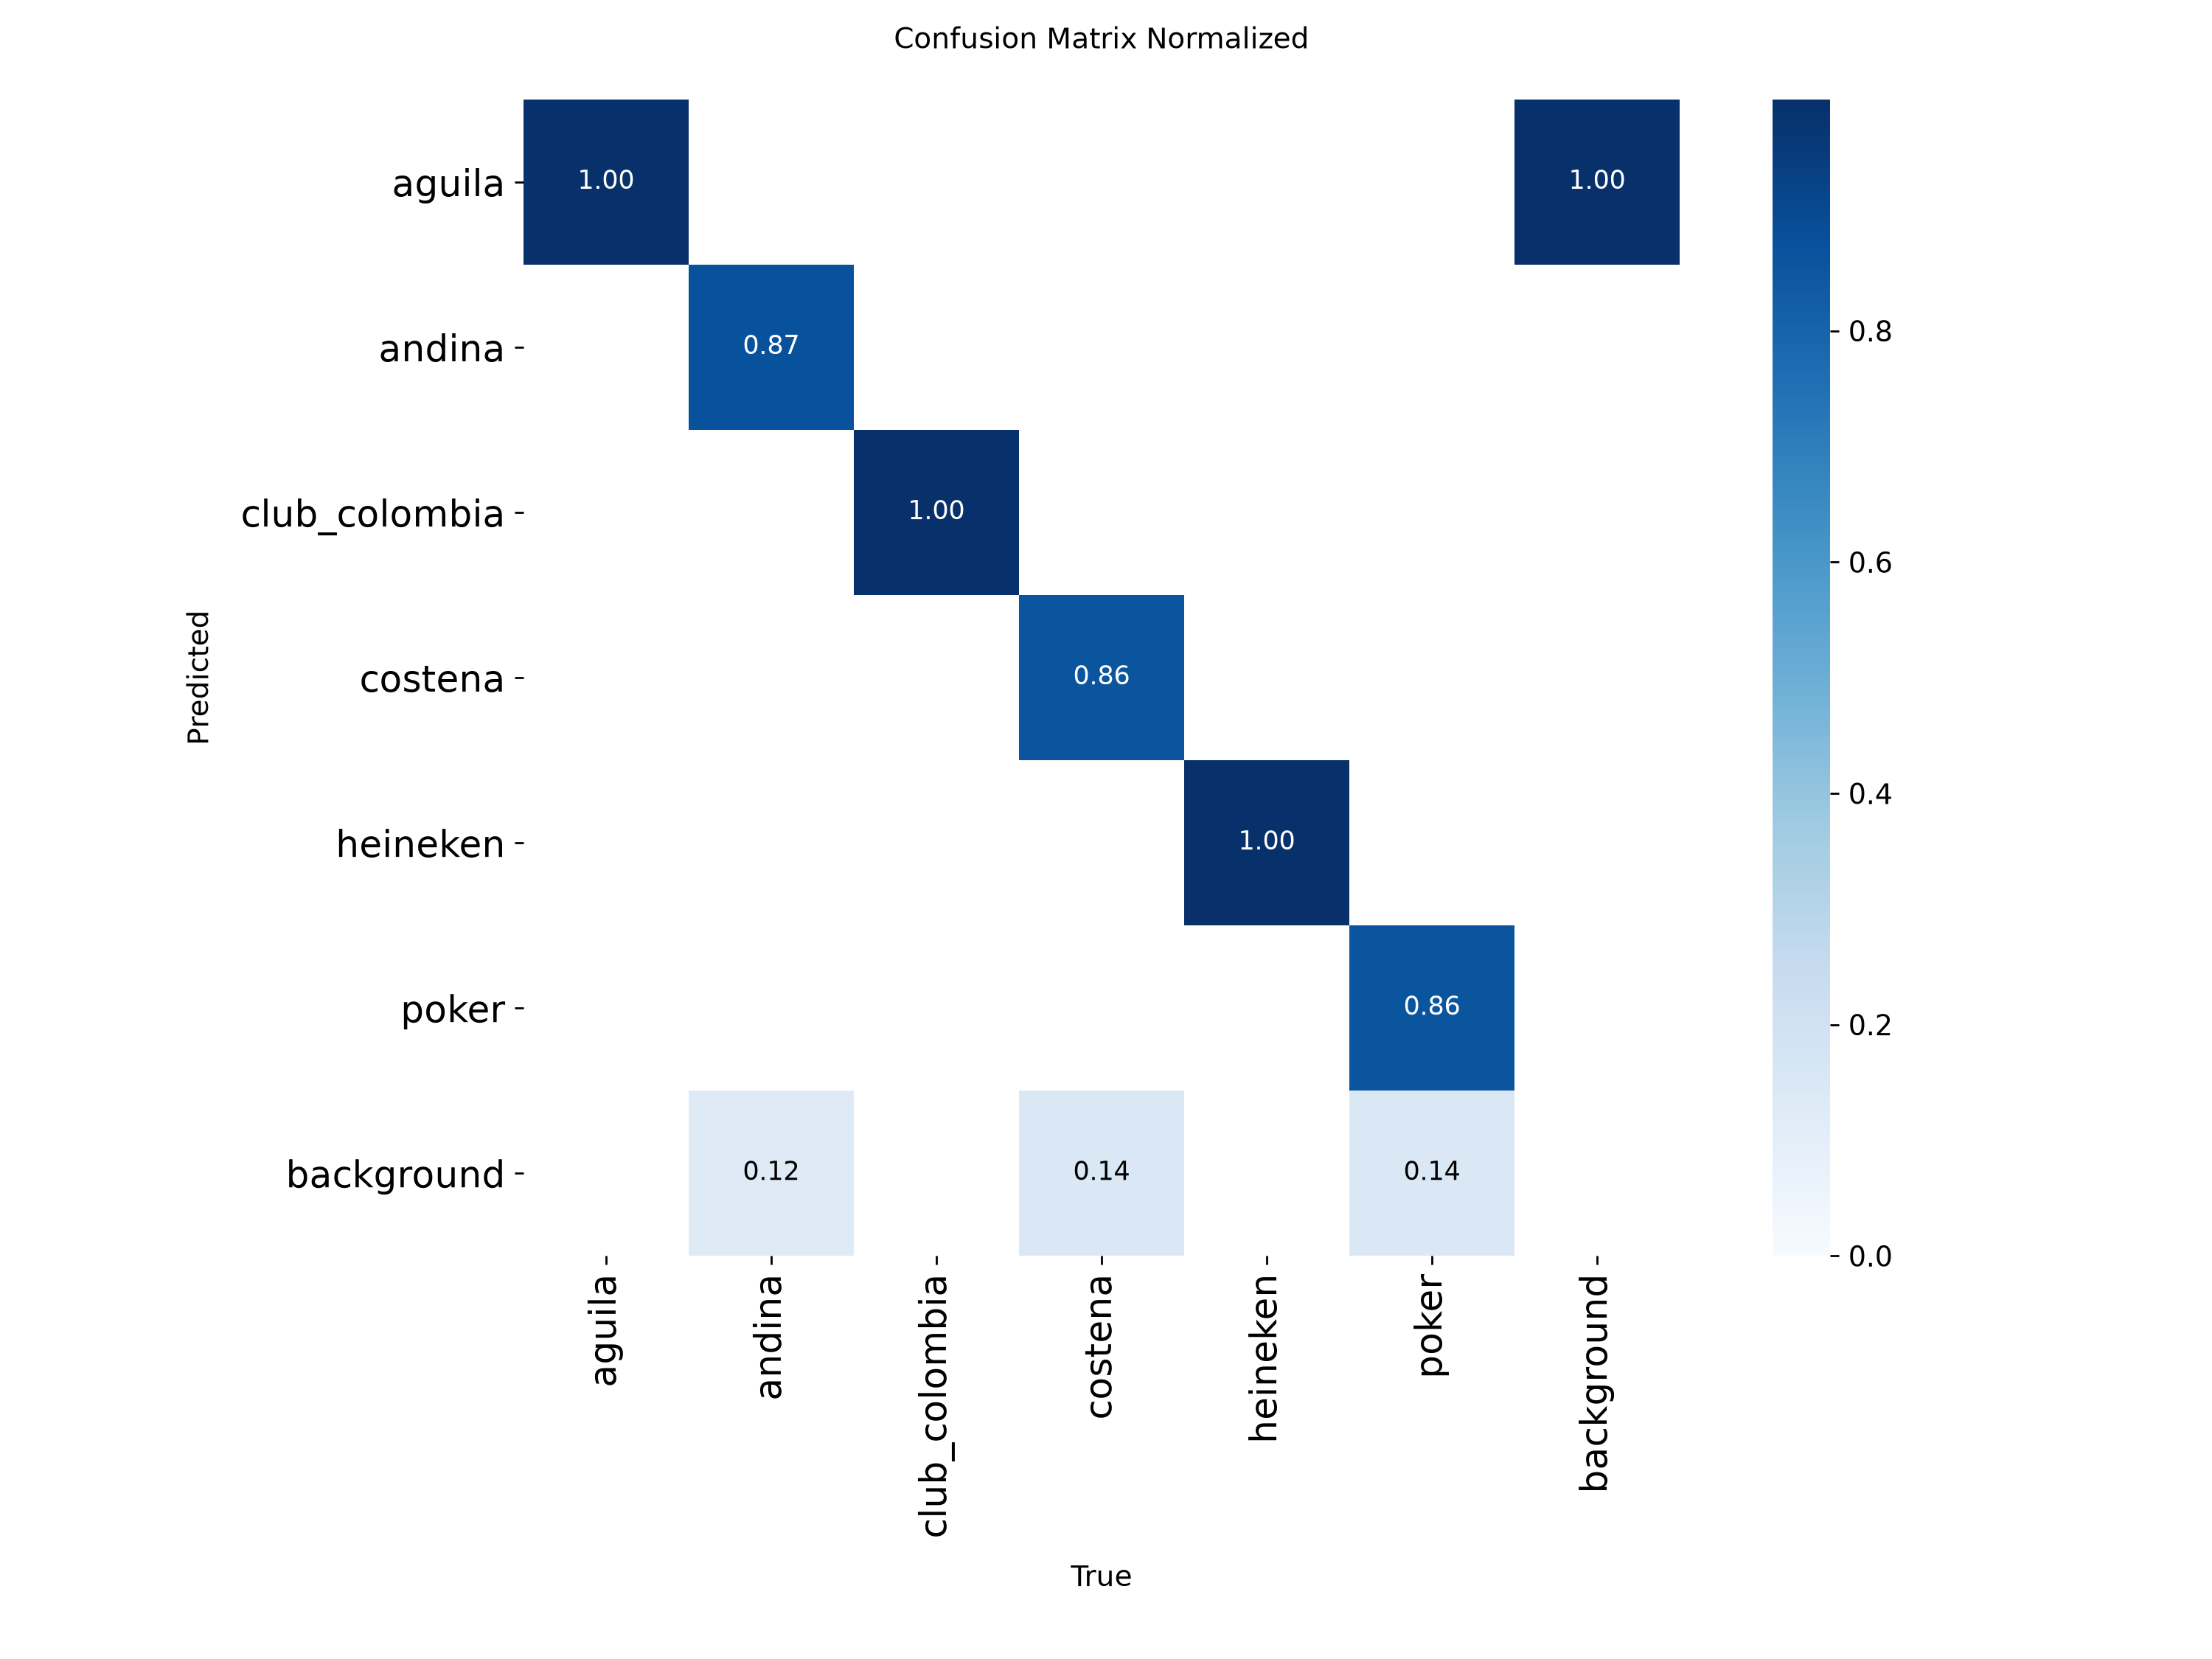

In [ ]:
m_corte_small = best_small.val(data=str(DATA_YAML), split="val", conf=CONF_MATRIZ, plots=True, device=DEVICE,
                                project=str(RUN_SMALL), name=f"val_conf{int(CONF_MATRIZ*100):02d}", exist_ok=True)
mostrar(RUN_SMALL / f"val_conf{int(CONF_MATRIZ*100):02d}" / "confusion_matrix.png", 800)
mostrar(RUN_SMALL / f"val_conf{int(CONF_MATRIZ*100):02d}" / "confusion_matrix_normalized.png", 800)

Ultralytics 8.4.196  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 559.8±263.6 MB/s, size: 50.0 KB)


val: Scanning C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\Datasets\cervezas-nao.v4-dataset-110-fotos-de-nosotros-v4.yolov8\test\labels.cache... 11 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 11/11  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.7it/s 0.2s

                   all         11         21      0.848      0.873      0.895      0.747


... (6 outputs left out)

Speed: 0.3ms preprocess, 12.9ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\small_v4\test


Results saved to C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\small_v4\pred_test


4_jpeg.rf.402c2a88f1a06390417250829975390b.jpg


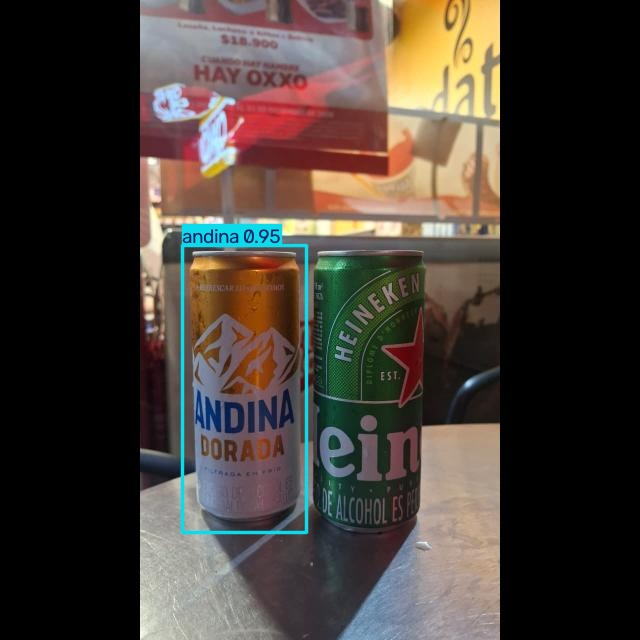

Foto8PR_jpeg.rf.115ac1a3fb77b0bf952b31c77e0c5e8c.jpg


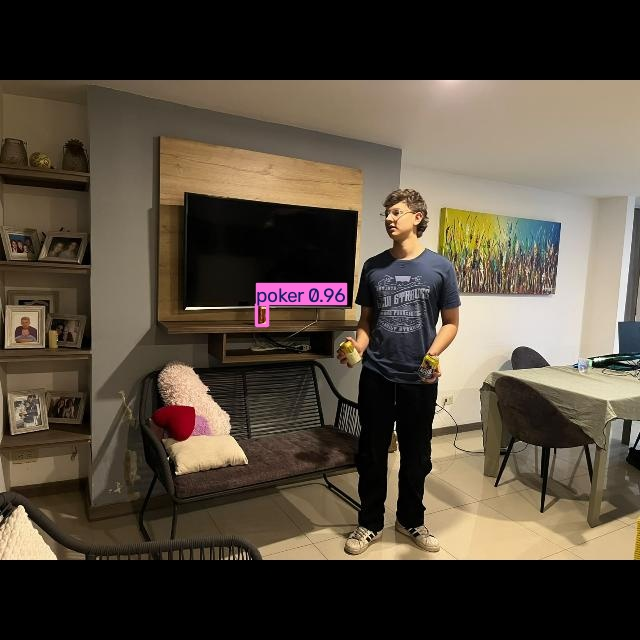

IMG_1725_jpeg.rf.3e582040a51fd14b4592c5b50af2e65c.jpg


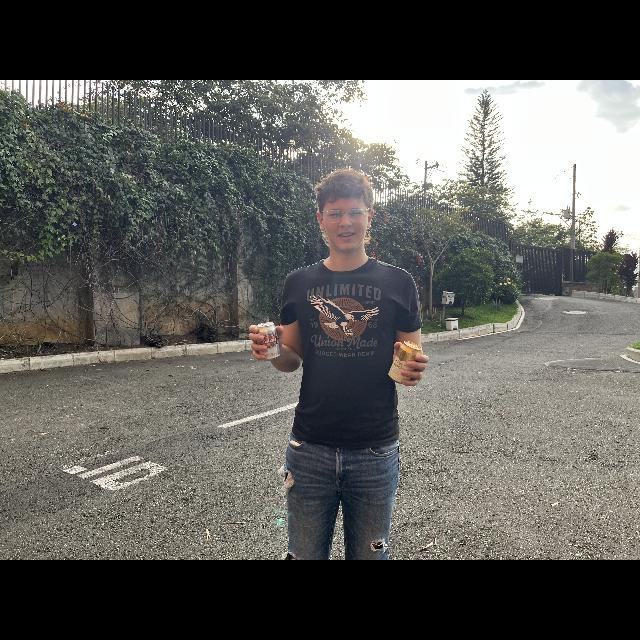

IMG_1750_jpeg.rf.080a8eca39c0ef776d06d4383e8f7652.jpg


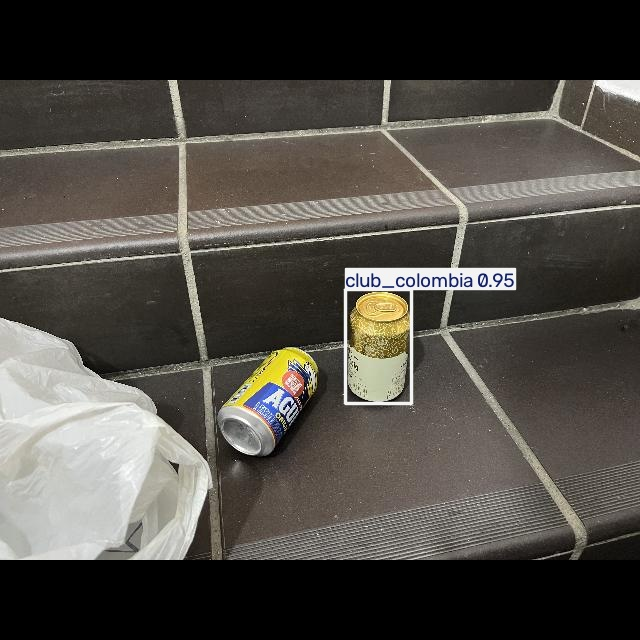

IMG_9914_EQF_jpeg.rf.44e7682a56d8650e54c5694ae374ab31.jpg


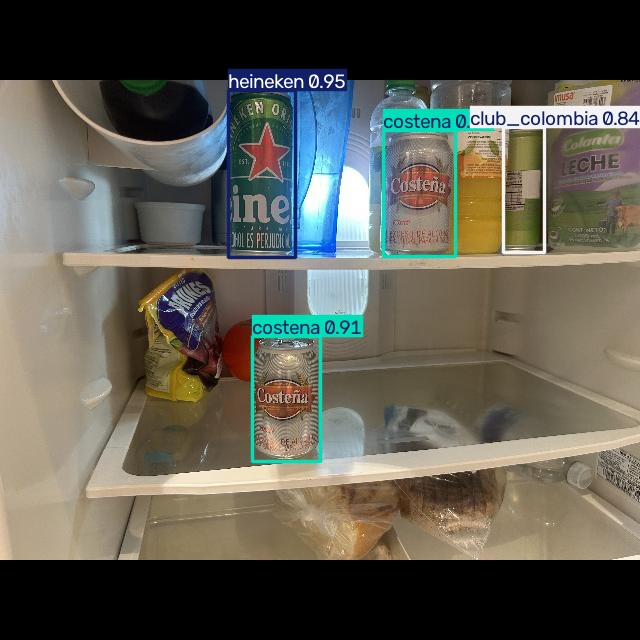

WhatsApp-Image-2026-10-27-at-10-52-18-PM-2-_jpeg.rf.3c37db9fad41b27c04c51615d057b8cd.jpg


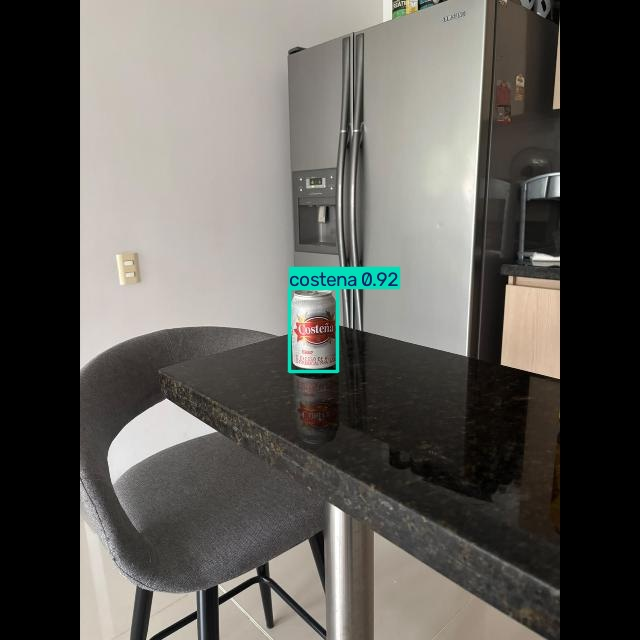

=== SMALL - test ===
P 0.848 | R 0.873 | mAP50 0.895 | mAP50-95 0.747 | mAP75 0.809
  aguila          P 0.74  R 0.50  mAP50 0.49  mAP50-95 0.45
  andina          P 0.66  R 1.00  mAP50 0.99  mAP50-95 0.90
  club_colombia   P 0.80  R 0.80  mAP50 0.90  mAP50-95 0.74
  costena         P 0.93  R 1.00  mAP50 0.99  mAP50-95 0.84
  heineken        P 0.96  R 1.00  mAP50 0.99  mAP50-95 0.81
  poker           P 1.00  R 0.94  mAP50 0.99  mAP50-95 0.75


In [21]:
test_small = probar_en_test(best_small, RUN_SMALL, CONF_SMALL)
if test_small:
    resumen(test_small, "SMALL - test")

## 7. Comparar nano vs. small y guardar los modelos
Para la demo importa **cuánto tarda cada frame**. La webcam del portátil de la presentación es de **1280×720
(720p, 16:9) a 30 fps**, así que se mide con un frame de ese tamaño. Para ir a 30 fps, cada frame debe tardar menos
de ~33 ms.

**Ojo:** esto mide la velocidad en el PC de Fraquiem. El portátil de la presentación es otro computador, así que
hay que volver a medir allá con la celda de la webcam (sección 8).

In [22]:
def velocidad(best, device, n=30):
    frame = cv2.resize(cv2.imread(image_paths[0]), (1280, 720))   # simula un frame de la webcam 720p
    for _ in range(3):
        best.predict(frame, imgsz=IMGSZ, device=device, verbose=False)
    t0 = time.perf_counter()
    for _ in range(n):
        best.predict(frame, imgsz=IMGSZ, device=device, verbose=False)
    ms = (time.perf_counter() - t0) / n * 1000
    return round(ms, 1)

filas = []
for nombre, best, mv, conf, run in [("nano", best_nano, metrics_nano, CONF_NANO, RUN_NANO),
                                    ("small", best_small, metrics_small, CONF_SMALL, RUN_SMALL)]:
    fila = {"modelo": nombre, "mAP50": round(mv.box.map50, 3), "mAP50_95": round(mv.box.map, 3),
            "P": round(mv.box.mp, 3), "R": round(mv.box.mr, 3), "conf_optima": round(conf, 2),
            "ms_cpu": velocidad(best, "cpu"), "ms_gpu": velocidad(best, 0) if GPU else ""}
    filas.append(fila)
    print(fila)

# Guardar copias con nombre claro para pasarlas al portátil de la presentación
MODELOS = path / "modelos"
MODELOS.mkdir(exist_ok=True)
shutil.copy2(RUN_NANO / "weights" / "best.pt", MODELOS / f"cervezas_nano_{VERSION}.pt")
shutil.copy2(RUN_SMALL / "weights" / "best.pt", MODELOS / f"cervezas_small_{VERSION}.pt")
with open(path / f"comparacion_{VERSION}.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(filas[0]))
    w.writeheader(); w.writerows(filas)
print("Modelos copiados en", MODELOS)

{'modelo': 'nano', 'mAP50': np.float64(0.99), 'mAP50_95': np.float64(0.884), 'P': np.float64(0.985), 'R': np.float64(0.949), 'conf_optima': 0.5, 'ms_cpu': 29.5, 'ms_gpu': 11.4}


{'modelo': 'small', 'mAP50': np.float64(0.964), 'mAP50_95': np.float64(0.854), 'P': np.float64(0.984), 'R': np.float64(0.917), 'conf_optima': 0.76, 'ms_cpu': 59.3, 'ms_gpu': 11.5}
Modelos copiados en C:\Users\Asus\Pedro\IA\ReconocimientoCervezas\02_entrenamiento_por_version\modelos


## 8. Prueba en tiempo real con la webcam (como `ProbarCamara.py`)
Pide a la cámara **1280×720 a 30 fps**, el formato de la presentación.

**Preprocesamiento de la imagen de la webcam al modelo:** OpenCV entrega cada frame como una matriz BGR de
720×1280×3, y YOLO la reescala sola a `IMGSZ` (640) **manteniendo la proporción** y rellenando los bordes. No hace
falta hacer nada a mano.

`USAR_TRACKING = True` activa el seguimiento con IDs (opcional; primero se prueba sin tracking). Se sale con **ESC**.

In [23]:
PROBAR_WEBCAM = False
MODELO_VIVO = best_nano          # o best_small
CONF_VIVO = CONF_NANO            # o CONF_SMALL
USAR_TRACKING = False

if PROBAR_WEBCAM:
    cap = cv2.VideoCapture(0)
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
    cap.set(cv2.CAP_PROP_FPS, 30)
    t_prev = time.perf_counter()
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if USAR_TRACKING:
            r = MODELO_VIVO.track(frame, persist=True, tracker="bytetrack.yaml", conf=CONF_VIVO,
                                  imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        else:
            r = MODELO_VIVO.predict(frame, conf=CONF_VIVO, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        vis = r.plot()
        t = time.perf_counter(); fps = 1 / (t - t_prev); t_prev = t
        cv2.putText(vis, f"{fps:.1f} FPS", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
        cv2.imshow("Cervezas - ESC para salir", vis)
        if cv2.waitKey(1) & 0xFF == 27:
            break
    cap.release()
    cv2.destroyAllWindows()

## 9. ¿Y si da mal? (lista para analizar)
1. **Revisar etiquetas:** latas sin caja, cajas flojas o con la clase equivocada (`train_batch0.jpg`,
   `val_batch0_labels.jpg`).
2. **Mirar la matriz de confusión:** ¿el error es con *background* o entre dos marcas? ¿Cuáles?
3. **Más datos:** fotos de internet de las marcas que fallan y más imágenes de fondo.
4. **Aumentos en Roboflow:** generar otra versión con aumentos distintos y reentrenar cambiando `VERSION`.
5. **Ajustar el umbral** de confianza si las detecciones de baja confianza son malas.
6. **Más épocas** (hasta 300) o un modelo más grande (`yolo26m.pt`).